# Sentimiento en noticias financieras y movimiento de precios

**Trabajo Práctico Integrador de Procesamiento de Lenguaje Natural**

Universidad de Palermo. Profesor Nicolás Rubinstein.

Grupo 10. Gastón Eduardo Echegoyen, Joaquín Rodriguez, Simón Martín Rubiño Montilla y Juan Pablo García Guerrero.

## La pregunta

Queremos saber si se puede clasificar automáticamente el sentimiento de las noticias financieras sobre
un conjunto acotado de acciones y, si se puede, si esa señal de texto tiene alguna relación con el
movimiento del precio en la ventana siguiente a la noticia.

Para acotar el trabajo nos quedamos solo con la clasificación de las noticias. El precio lo usamos
como referencia para evaluar y no entra en ningún modelo. La comparación central es entre un baseline
clásico (TF-IDF con un clasificador lineal) y versiones con embeddings y con un LLM. Sumamos FinBERT,
un BERT ajustado para finanzas, porque es la referencia habitual en este problema.

No etiquetamos nada a mano. Para entrenar y medir usamos dos datasets públicos que ya vienen
etiquetados, y las noticias reales, que no tienen etiqueta, las evaluamos contra el precio.

## Recorrido

1. Datos etiquetados (Financial PhraseBank y Twitter Financial News), exploración y partición.
2. Baseline con TF-IDF y regresión logística o SVM lineal.
3. Cambio de dominio, es decir, qué pasa si entrenamos con una fuente y evaluamos en la otra.
4. Embeddings de oraciones con regresión logística.
5. FinBERT sin reentrenar.
6. Gemini sin ajuste, en zero-shot y few-shot.
7. Comparación de todos los modelos sobre los mismos textos.
8. Noticias reales de 8 acciones y sus precios.
9. Relación entre la señal de texto y el precio.
10. Conclusiones y limitaciones.

## Resultado

La clasificación funciona, pero ningún modelo gana en todos los casos. En el test de Twitter, que es el
más parecido a los titulares reales, el baseline de TF-IDF es el mejor (F1 macro de 0,77) y supera a
FinBERT y a Gemini por unos 10 puntos, con diferencias significativas. En PhraseBank ganan los
embeddings (0,90), seguidos por Gemini few-shot (0,88). La diferencia más grande aparece con el cambio
de dominio. TF-IDF entrenado solo con PhraseBank cae a 0,44 en Twitter, mientras que los embeddings se
sostienen en 0,67.

Sobre 9.079 titulares reales de 8 acciones, la señal de sentimiento se relaciona con fuerza con el
precio del mismo día y del día anterior. Los titulares positivos vienen con retornos anormales unos
140 pb mayores que los negativos. En la ventana siguiente, en cambio, ninguno de los cinco modelos
muestra una relación positiva, y el acierto de dirección queda entre 44 % y 49 %. Los titulares cuentan
lo que el precio ya hizo, pero no lo anticipan.

> Para correr la notebook en Colab hace falta un entorno con GPU T4, la carpeta `TP-Integrador-PLN` en
> *Mi unidad* de Drive y la clave de la API de Gemini cargada en *Secrets* con el nombre `GEMINI_API_KEY`.

## 0. Preparación del entorno

Colab ya trae casi todo lo que usamos (pandas, scikit-learn, transformers y sentence-transformers).
Actualizamos `google-genai` porque hace falta una versión reciente para configurar el nivel de
razonamiento de los modelos Gemini 3.

In [3]:
!pip install -q -U google-genai yfinance sentence-transformers

In [4]:
import json, re, time, hashlib, zipfile, warnings
from pathlib import Path
from datetime import datetime, timedelta, timezone
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 100)

# En Colab trabajamos sobre la carpeta del proyecto en Drive, así lo descargado y las respuestas
# del LLM quedan guardadas entre sesiones y no se repiten.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/TP-Integrador-PLN")
except ImportError:
    RAIZ = Path(".").resolve()

DATOS = RAIZ / "data" / "cache"
RESULTADOS = RAIZ / "resultados"
BITACORA = RESULTADOS / "bitacora_llm"
for carpeta in [DATOS, RESULTADOS / "metricas", RESULTADOS / "figuras", BITACORA]:
    carpeta.mkdir(parents=True, exist_ok=True)

SEMILLA = 42                      # una sola semilla para todo, así los resultados se pueden reproducir
ETIQUETAS = ["positivo", "negativo", "neutro"]
np.random.seed(SEMILLA)

# Estilo de los gráficos y un color fijo por familia de modelo
AZUL, NARANJA, VERDE, OCRE = "#1A6FB5", "#C8651B", "#1B8A5A", "#B08900"
TINTA, TENUE = "#22282E", "#8A9299"
COLOR_CLASE = {"positivo": VERDE, "negativo": NARANJA, "neutro": TENUE}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TENUE, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": TENUE, "ytick.color": TENUE,
    "grid.color": "#E3E6E8", "grid.linewidth": 0.8, "axes.grid": True, "axes.axisbelow": True,
})
print("carpeta del proyecto:", RAIZ)

Mounted at /content/drive
carpeta del proyecto: /content/drive/MyDrive/TP-Integrador-PLN


## 1. Datos etiquetados

Usamos dos datasets públicos de sentimiento financiero en inglés, los dos con tres clases.

- **Financial PhraseBank** (Malo et al., 2014). Son unas 4.800 oraciones de noticias financieras
  etiquetadas por 16 personas con formación en finanzas y economía. Cada oración trae el nivel de
  acuerdo entre anotadores, y usamos el subconjunto con acuerdo de al menos 75 %, que descarta las
  oraciones en las que ni los expertos coincidían.
- **Twitter Financial News Sentiment** (dataset `zeroshot` de Hugging Face). Son unos 12.000 titulares
  y tuits de cuentas de noticias de mercado, etiquetados como *Bearish*, *Bullish* o *Neutral*.

Elegimos dos fuentes a propósito. PhraseBank tiene oraciones de redacción formal sacadas del cuerpo de
la noticia, y Twitter tiene titulares cortos, con cashtags (`$AAPL`) y abreviaturas, mucho más
parecidos a los titulares reales que clasificamos en la sección 8. Con las dos podemos medir cuánto
cambia el desempeño cuando cambia el estilo del texto (sección 3).

Unificamos las etiquetas en positivo, negativo y neutro, con *Bullish* como positivo y *Bearish* como
negativo.

In [5]:
from huggingface_hub import hf_hub_download
from datasets import load_dataset

def descargar_phrasebank():
    try:
        ruta = hf_hub_download("takala/financial_phrasebank", "data/FinancialPhraseBank-v1.0.zip",
                               repo_type="dataset")
        with zipfile.ZipFile(ruta) as z:
            nombre = [n for n in z.namelist() if n.endswith("Sentences_75Agree.txt")][0]
            lineas = z.read(nombre).decode("latin-1").splitlines()
        mapeo = {"positive": "positivo", "negative": "negativo", "neutral": "neutro"}
        filas = []
        for linea in lineas:
            if "@" in linea:                       # cada línea tiene la forma "oración@etiqueta"
                oracion, etiqueta = linea.rsplit("@", 1)
                filas.append({"texto": oracion.strip(), "etiqueta": mapeo[etiqueta.strip()]})
        return pd.DataFrame(filas)
    except Exception as e:
        # si el zip no está disponible, el Hub tiene la misma tabla convertida a parquet
        print("zip no disponible, uso la versión parquet:", str(e)[:80])
        pb = load_dataset("takala/financial_phrasebank", "sentences_75agree",
                          revision="refs/convert/parquet", split="train").to_pandas()
        mapeo = {0: "negativo", 1: "neutro", 2: "positivo"}
        return pd.DataFrame({"texto": pb["sentence"], "etiqueta": pb["label"].map(mapeo)})

def descargar_twitter():
    tw = load_dataset("zeroshot/twitter-financial-news-sentiment")
    mapeo = {0: "negativo", 1: "positivo", 2: "neutro"}     # 0 Bearish, 1 Bullish, 2 Neutral
    convertir = lambda parte: pd.DataFrame({"texto": parte["text"],
                                            "etiqueta": [mapeo[x] for x in parte["label"]]})
    return convertir(tw["train"]), convertir(tw["validation"])

if not (DATOS / "phrasebank.csv").exists():
    descargar_phrasebank().to_csv(DATOS / "phrasebank.csv", index=False)
    tw_train, tw_test = descargar_twitter()
    tw_train.to_csv(DATOS / "twitter_train.csv", index=False)
    tw_test.to_csv(DATOS / "twitter_test.csv", index=False)

phrasebank = pd.read_csv(DATOS / "phrasebank.csv", keep_default_na=False)
twitter_train = pd.read_csv(DATOS / "twitter_train.csv", keep_default_na=False)
twitter_test = pd.read_csv(DATOS / "twitter_test.csv", keep_default_na=False)
print(f"PhraseBank (75 % de acuerdo): {len(phrasebank)} oraciones")
print(f"Twitter: {len(twitter_train)} de entrenamiento y {len(twitter_test)} de validación oficial")

PhraseBank (75 % de acuerdo): 3453 oraciones
Twitter: 9543 de entrenamiento y 2388 de validación oficial


### Exploración

Antes de modelar miramos cómo se reparten las clases, qué tan largos son los textos y cómo se ven
algunos ejemplos de cada clase.

,PhraseBank,Twitter
etiqueta,,
positivo,0.257,0.201
negativo,0.122,0.150
neutro,0.621,0.649


,PhraseBank,Twitter
media,22.8,12.2
mediana,21.0,12.0
min,2.0,1.0
max,81.0,33.0


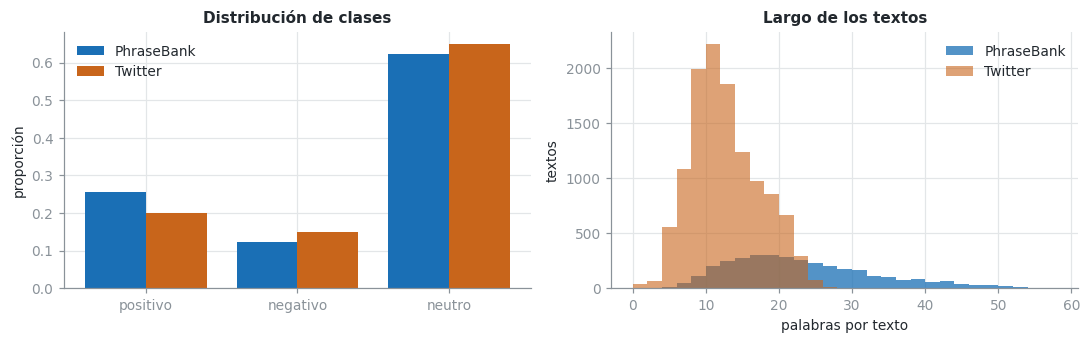

In [6]:
twitter = pd.concat([twitter_train, twitter_test])
dist = pd.DataFrame({
    "PhraseBank": phrasebank["etiqueta"].value_counts(normalize=True),
    "Twitter": twitter["etiqueta"].value_counts(normalize=True),
}).loc[ETIQUETAS]
largo = pd.DataFrame({
    "PhraseBank": phrasebank["texto"].str.split().str.len().describe(),
    "Twitter": twitter["texto"].str.split().str.len().describe(),
}).loc[["mean", "50%", "min", "max"]].rename(index={"mean": "media", "50%": "mediana"})

display(dist.round(3))
display(largo.round(1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
x = np.arange(len(ETIQUETAS))
ax1.bar(x - 0.2, dist["PhraseBank"], width=0.4, color=AZUL, label="PhraseBank")
ax1.bar(x + 0.2, dist["Twitter"], width=0.4, color=NARANJA, label="Twitter")
ax1.set_xticks(x, ETIQUETAS)
ax1.set_ylabel("proporción")
ax1.legend(frameon=False)
ax1.set_title("Distribución de clases")
ax2.hist(phrasebank["texto"].str.split().str.len(), bins=range(0, 60, 2), color=AZUL, alpha=0.75, label="PhraseBank")
ax2.hist(twitter["texto"].str.split().str.len(), bins=range(0, 60, 2), color=NARANJA, alpha=0.6, label="Twitter")
ax2.set_xlabel("palabras por texto")
ax2.set_ylabel("textos")
ax2.legend(frameon=False)
ax2.set_title("Largo de los textos")
plt.tight_layout()
plt.show()

In [7]:
for nombre, df in [("PhraseBank", phrasebank), ("Twitter", twitter_train)]:
    print(f"--- {nombre}")
    for e in ETIQUETAS:
        for t in df[df["etiqueta"] == e]["texto"].sample(2, random_state=1):
            print(f"  [{e:8s}] {t[:120]}")

--- PhraseBank
  [positivo] SKF 6 April 2010 - Alandsbanken has given a `` buy '' recommendation on Swedish industrial company SKF AB ( STO : SKF B 
  [positivo] The total delivery volume of paper businesses in 2010 was 1,155,000 tonnes , up from 1,132,000 tonnes in 2009 .
  [negativo] ADPnews - Sep 28 , 2009 - Finnish silicon wafers maker Okmetic Oyj HEL : OKM1V said it will reduce the number of its cle
  [negativo] Net sales have been eaten by the weak US dollar .
  [neutro  ] Nordea Bank AB publ holds 6.000 Alma Media shares , representing 0.008 % of share capital and voting rights .
  [neutro  ] Auburn 's sales in 2007 were CAD 41 million ( approximately EUR 27 million ) , and the company employs some 150 people .
--- Twitter
  [positivo] Analyst: AT&T Is The Top Telecom Pick For 2020
  [positivo] Rally goes on as China cuts U.S. tariffs
  [negativo] Why China's coronavirus is more dangerous for the global economy than SARS was in 2003 https://t.co/diuqsVLFOD via @BW
  [negativo] T

Las dos fuentes reparten las clases de forma parecida. Neutro es la mayoría (62 % en PhraseBank y
65 % en Twitter) y negativo es la clase más chica (12 % y 15 %). Ese desbalance es lo que justifica
usar F1 macro y `class_weight="balanced"` más adelante.

Donde más se diferencian es en la forma. Las oraciones de PhraseBank tienen 23 palabras en promedio,
con cifras, monedas y nombres de empresas finlandesas, porque salen de noticias sobre empresas que
cotizan en Helsinki. Los tuits tienen 12 palabras en promedio, traen cashtags y links, y por los temas
que tratan (el coronavirus, la guerra comercial con China, los resultados del cuarto trimestre de 2019)
son de 2019 y 2020.

Los ejemplos también muestran que el criterio de neutro de Twitter es amplio. *"Another fatality at
Great Panther Mining"* está etiquetado como neutro, y esto va a importar cuando comparemos con el LLM.

### Limpieza y partición

Los tuits traen links acortados (`https://t.co/...`) que no aportan nada y que, como son únicos, solo
agregan ruido al vocabulario. Los sacamos. No hacemos más preprocesamiento. No sacamos stop-words ni
hacemos stemming porque en sentimiento palabras como *not*, *up* o *down* son justamente las que
importan, y los modelos basados en transformers esperan el texto original.

Twitter ya trae una partición de validación, que usamos como test. Del resto separamos un 15 % como
dev para elegir hiperparámetros. PhraseBank no trae partición, así que la armamos nosotros con un 15 %
para test y, del resto, un 15 % para dev, siempre estratificado por clase. El test se usa una sola vez,
al final de cada modelo.

Los mismos titulares circulan en varias fuentes y a veces se repiten con otra capitalización o
puntuación. Si un texto del test también está en entrenamiento, la métrica deja de medir
generalización. Por eso normalizamos los textos y sacamos de train y dev todo lo que aparezca en algún
test.

In [8]:
from sklearn.model_selection import train_test_split

def limpiar_tuit(t):
    t = re.sub(r"https?://\S+", "", str(t))
    return re.sub(r"\s+", " ", t).strip()

def normalizar(t):
    t = re.sub(r"[^\w\s%$.,-]", "", str(t).lower())
    return re.sub(r"\s+", " ", t).strip()

def particionar(df, fuente, test=None):
    df = df.drop_duplicates("texto").reset_index(drop=True)
    if test is None:
        resto, test = train_test_split(df, test_size=0.15, stratify=df["etiqueta"], random_state=SEMILLA)
    else:
        resto, test = df, test.drop_duplicates("texto")
    train, dev = train_test_split(resto, test_size=0.15, stratify=resto["etiqueta"], random_state=SEMILLA)
    out = pd.concat([train.assign(split="train"), dev.assign(split="dev"), test.assign(split="test")],
                    ignore_index=True).assign(fuente=fuente)
    out.insert(0, "id", [f"{fuente[:2]}_{i:05d}" for i in range(len(out))])
    return out[["id", "texto", "etiqueta", "fuente", "split"]]

tw_train, tw_test = twitter_train.copy(), twitter_test.copy()
tw_train["texto"] = tw_train["texto"].map(limpiar_tuit)
tw_test["texto"] = tw_test["texto"].map(limpiar_tuit)

d = pd.concat([particionar(phrasebank, "phrasebank"),
               particionar(tw_train, "twitter", test=tw_test)], ignore_index=True)

# fuga de información, textos de train o dev que (normalizados) también están en algún test
norm = d["texto"].map(normalizar)
fuga = (d["split"] != "test") & norm.isin(set(norm[d["split"] == "test"]))
print(f"textos de train/dev repetidos en test: {fuga.sum()}  -> se descartan")
d = d[~fuga].reset_index(drop=True)
d = d[d["texto"].str.len() > 5].reset_index(drop=True)

d.groupby(["fuente", "split", "etiqueta"]).size().unstack(fill_value=0)

textos de train/dev repetidos en test: 42  -> se descartan


etiqueta          negativo  neutro  positivo
fuente     split                            
phrasebank dev          54     273       113
           test         63     322       133
           train       303    1546       641
twitter    dev         214     907       286
           test        345    1552       475
           train      1204    5137      1619

Aparecieron 42 textos de train o dev repetidos en algún test y los sacamos. Quedan 15.187 textos.
PhraseBank queda con 2.490 en train, 440 en dev y 518 en test, y Twitter con 7.960, 1.407 y 2.372. Las
proporciones de clase se mantienen en cada partición gracias a la estratificación.

## 2. Baseline con TF-IDF y un clasificador lineal

Es el baseline del plan de trabajo. Representamos cada texto con TF-IDF y combinamos dos vocabularios.

- **Palabras sueltas y pares de palabras** (uni y bigramas). Los bigramas capturan expresiones como
  *"net loss"*, *"beats estimates"* o *"not profitable"*, en las que una palabra sola cambia de sentido.
- **N-gramas de caracteres** de 2 a 5 (`char_wb`). Ayudan con las variantes de una misma palabra
  (*rise, rises, rising*), con las abreviaturas y con los errores de tipeo de los tuits.

Usamos `sublinear_tf=True`, que toma el logaritmo de la frecuencia, para que una palabra repetida no
domine el vector.

Sobre esa representación entrenamos dos clasificadores lineales vistos en el módulo 6, la regresión
logística y la SVM lineal. Los dos llevan `class_weight="balanced"` porque la clase neutra es mayoría
en los dos datasets y, sin esa corrección, el modelo tiende a predecir neutro de más.

Como métrica usamos F1 macro, que es el promedio del F1 de las tres clases con el mismo peso para cada
una. La exactitud premiaría a un modelo que acierta mucho en neutro y falla en las clases que nos
interesan, que son positivo y negativo. A cada F1 le agregamos un intervalo de confianza del 95 % por
bootstrap. Remuestreamos los textos del test 1.000 veces y vemos cuánto varía la métrica. Si los
intervalos de dos modelos se pisan mucho, la diferencia entre ellos puede ser ruido.

El hiperparámetro de regularización C se elige en dev y nunca en test.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

def particion(fuentes, split):
    return d[d["fuente"].isin(fuentes) & (d["split"] == split)]

def ic_bootstrap(y, p, n=1000):
    # intervalo del 95 % del F1 macro remuestreando los textos del test
    y, p = np.asarray(y), np.asarray(p)
    rng = np.random.default_rng(SEMILLA)
    valores = [f1_score(y[i], p[i], labels=ETIQUETAS, average="macro", zero_division=0)
               for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.quantile(valores, [0.025, 0.975])

# acá guardamos cada evaluación (modelo, con qué se entrenó y en qué test) y sus predicciones
resultados, predicciones = [], {}

def evaluar(sistema, entrenamiento, test_nombre, df_test, pred, seg_por_1000=None):
    y = df_test["etiqueta"].tolist()
    inf, sup = ic_bootstrap(y, pred)
    fila = {"sistema": sistema, "entrenamiento": entrenamiento, "test": test_nombre,
            "f1_macro": f1_score(y, pred, labels=ETIQUETAS, average="macro"), "ic_inf": inf, "ic_sup": sup,
            "exactitud": accuracy_score(y, pred), "n": len(y), "seg_por_1000": seg_por_1000}
    resultados.append(fila)
    predicciones[(sistema, entrenamiento, test_nombre)] = pd.Series(list(pred), index=df_test["id"].values)
    return fila

GRILLA_C = [0.1, 0.3, 1, 3, 10]

def ajustar_eligiendo_C(crear_clf, X_train, y_train, X_dev, y_dev):
    curva = []
    for C in GRILLA_C:
        pred_dev = crear_clf(C).fit(X_train, y_train).predict(X_dev)
        curva.append({"C": C, "f1_dev": f1_score(y_dev, pred_dev, average="macro")})
    curva = pd.DataFrame(curva)
    mejor_C = curva.loc[curva["f1_dev"].idxmax(), "C"]
    return crear_clf(mejor_C).fit(X_train, y_train), curva

def nuevo_tfidf():
    return FeatureUnion([
        ("palabras", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("caracteres", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                                       sublinear_tf=True, max_features=60000)),
    ])

CLASIFICADORES = {
    "TF-IDF + reg. logística": lambda C: LogisticRegression(C=C, max_iter=3000, class_weight="balanced"),
    "TF-IDF + SVM lineal": lambda C: LinearSVC(C=C, class_weight="balanced"),
}
TESTS = {"PhraseBank": particion(["phrasebank"], "test"), "Twitter": particion(["twitter"], "test")}

Primero entrenamos con las dos fuentes juntas. Este es el modelo que después clasifica las noticias
reales.

dimensiones del vector TF-IDF: 68,323


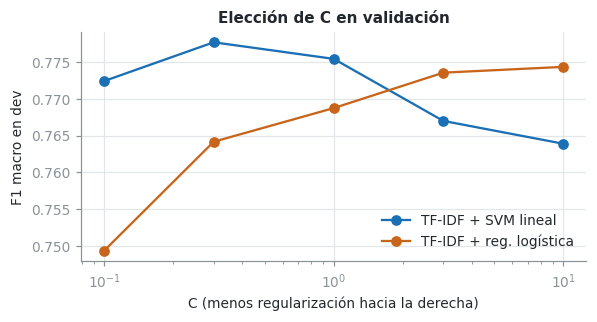

,sistema,entrenamiento,test,f1_macro,ic_inf,ic_sup,exactitud,n,seg_por_1000
0,TF-IDF + reg. logística,las dos fuentes,PhraseBank,0.835,0.794,0.871,0.867,518,0.524
1,TF-IDF + reg. logística,las dos fuentes,Twitter,0.760,0.737,0.779,0.818,2372,0.343
2,TF-IDF + SVM lineal,las dos fuentes,PhraseBank,0.842,0.804,0.880,0.869,518,0.558
3,TF-IDF + SVM lineal,las dos fuentes,Twitter,0.768,0.747,0.789,0.828,2372,0.314


In [10]:
train, dev = particion(["phrasebank", "twitter"], "train"), particion(["phrasebank", "twitter"], "dev")
tfidf = nuevo_tfidf()
X_train = tfidf.fit_transform(train["texto"])        # el vocabulario se aprende solo con train
X_dev = tfidf.transform(dev["texto"])
print(f"dimensiones del vector TF-IDF: {X_train.shape[1]:,}")

modelos_finales, curvas = {}, []
for nombre, crear in CLASIFICADORES.items():
    modelo, curva = ajustar_eligiendo_C(crear, X_train, train["etiqueta"], X_dev, dev["etiqueta"])
    modelos_finales[nombre] = (tfidf, modelo)
    curvas.append(curva.assign(modelo=nombre))
    for test_nombre, test in TESTS.items():
        t0 = time.perf_counter()
        pred = modelo.predict(tfidf.transform(test["texto"]))
        seg = (time.perf_counter() - t0) / len(test) * 1000
        evaluar(nombre, "las dos fuentes", test_nombre, test, pred, seg)

curvas = pd.concat(curvas)
fig, ax = plt.subplots(figsize=(5.5, 3))
for (nombre, c), color in zip(curvas.groupby("modelo"), [AZUL, NARANJA]):
    ax.plot(c["C"], c["f1_dev"], marker="o", color=color, label=nombre)
ax.set_xscale("log")
ax.set_xlabel("C (menos regularización hacia la derecha)")
ax.set_ylabel("F1 macro en dev")
ax.set_title("Elección de C en validación")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

pd.DataFrame(resultados).round(3)

In [11]:
tfidf, logreg = modelos_finales["TF-IDF + reg. logística"]
pred = logreg.predict(tfidf.transform(TESTS["Twitter"]["texto"]))
print(classification_report(TESTS["Twitter"]["etiqueta"], pred, labels=ETIQUETAS, digits=3))

              precision    recall  f1-score   support

    positivo      0.739     0.752     0.745       475
    negativo      0.642     0.670     0.655       345
      neutro      0.885     0.872     0.878      1552

    accuracy                          0.818      2372
   macro avg      0.755     0.764     0.760      2372
weighted avg      0.820     0.818     0.819      2372



### Qué aprendió el baseline

Una ventaja de la regresión logística es que se puede leer, porque cada término tiene un coeficiente por
clase. Miramos las palabras y bigramas con más peso en cada clase y dejamos afuera los n-gramas de
caracteres, que son difíciles de interpretar.

In [12]:
nombres = tfidf.get_feature_names_out()
es_palabra = np.char.startswith(nombres.astype(str), "palabras__")
filas = {}
for i, clase in enumerate(logreg.classes_):
    coef = np.where(es_palabra, logreg.coef_[i], -np.inf)
    filas[clase] = [nombres[j].replace("palabras__", "") for j in np.argsort(coef)[::-1][:15]]
pd.DataFrame(filas)[ETIQUETAS]

,positivo,negativo,neutro
0,up,down,but
1,rises,decreased,how
2,rose,misses,or
3,up from,lower,trump
4,grew,target cut,stocks that
5,increased,fell,his
6,beats on,misses on,strong action
7,signed,hit,declares
8,higher,sues,stock marketscreener
9,raised,bear,no


Entrenado con las dos fuentes, el baseline llega a un F1 macro de 0,835 con regresión logística y 0,842
con SVM en PhraseBank, y de 0,760 y 0,768 en Twitter. Twitter es más difícil, y la clase que peor sale es
negativo (F1 de 0,655), que es la más chica.

En dev, la SVM rinde mejor con C = 0,3 y la regresión logística con C = 10. Para la regresión logística
ese valor es el extremo de la grilla, así que un C más grande podría rendir algo más, aunque la curva ya
casi no sube entre 3 y 10.

Las palabras con más peso tienen sentido financiero. En positivo aparecen verbos de suba y de resultados
(*up, rises, rose, grew, increased, beats on, raised, tops*) y en negativo sus opuestos (*down,
decreased, misses, lower, target cut, fell, sues, downgraded, weighs on*). La clase neutro se lee peor.
El modelo la aprende sobre todo como ausencia de esas palabras, más algunos rasgos de estilo (*but, how,
or*). También aparecen *trump* e *in trade*, que reflejan la época del dataset de Twitter, cuando muchas
noticias políticas se etiquetaron como neutras. Es una correlación espuria que no tiene por qué valer
para titulares de 2026.

## 3. Cambio de dominio

Las noticias reales que vamos a clasificar no son oraciones de PhraseBank ni tuits, sino titulares de
medios. Antes de confiar en el modelo queremos saber cuánto se degrada cuando el texto de evaluación
tiene un estilo distinto al de entrenamiento. Para eso repetimos el entrenamiento con una sola fuente y
evaluamos en las dos.

In [13]:
for fuente_train in ["phrasebank", "twitter"]:
    train, dev = particion([fuente_train], "train"), particion([fuente_train], "dev")
    vec = nuevo_tfidf()
    Xtr, Xdv = vec.fit_transform(train["texto"]), vec.transform(dev["texto"])
    for nombre, crear in CLASIFICADORES.items():
        modelo, _ = ajustar_eligiendo_C(crear, Xtr, train["etiqueta"], Xdv, dev["etiqueta"])
        for test_nombre, test in TESTS.items():
            evaluar(nombre, f"solo {fuente_train}", test_nombre, test, modelo.predict(vec.transform(test["texto"])))

def tabla_dominio(sistemas):
    t = pd.DataFrame(resultados)
    t = t[t["sistema"].isin(sistemas)]
    return t.pivot_table(index=["sistema", "entrenamiento"], columns="test", values="f1_macro").round(3)

tabla_dominio(list(CLASIFICADORES))

test                                     PhraseBank  Twitter
sistema                 entrenamiento                       
TF-IDF + SVM lineal     las dos fuentes       0.842    0.768
                        solo phrasebank       0.821    0.456
                        solo twitter          0.584    0.762
TF-IDF + reg. logística las dos fuentes       0.835    0.760
                        solo phrasebank       0.828    0.443
                        solo twitter          0.604    0.759

El cambio de dominio es el resultado más fuerte de esta parte. Entrenado solo con PhraseBank, el baseline
cae en Twitter de 0,76 a 0,44 o 0,46. Entrenado solo con Twitter, cae en PhraseBank de 0,83 a 0,58 o
0,60. TF-IDF depende del vocabulario exacto que vio, y las oraciones formales de PhraseBank (*operating
profit, EUR mn*) y los titulares de Twitter casi no comparten los términos que indican el sentimiento.

Entrenar con las dos fuentes juntas recupera en cada test lo mismo que se obtiene entrenando solo con esa
fuente. Mezclar no cuesta nada, así que ese es el modelo que usamos para las noticias reales. De todas
formas, esos titulares son un tercer dominio, y lo esperable es que el desempeño real ahí sea algo menor
que el que medimos en estos tests.

## 4. Embeddings de oraciones con regresión logística

TF-IDF solo conoce las palabras que vio en entrenamiento, y para él *"plunges"* y *"tumbles"* son dos
columnas distintas sin relación entre sí. Un modelo de embeddings de oraciones convierte cada texto en
un vector denso en el que los textos con significado parecido quedan cerca, aunque no compartan
palabras.

Usamos `all-mpnet-base-v2` (sentence-transformers), un modelo general y no financiero, y lo dejamos
congelado. No lo reentrenamos, sino que lo usamos como extractor de features y encima entrenamos la
misma regresión logística de antes. Es transfer learning en su forma más simple, como en el módulo de
embeddings. Los vectores salen normalizados con norma 1, así que el producto escalar entre dos de ellos
es la similitud coseno.

In [14]:
from sentence_transformers import SentenceTransformer

MODELO_EMB = "sentence-transformers/all-mpnet-base-v2"
codificador = SentenceTransformer(MODELO_EMB)

def embeddings(textos, nombre_cache):
    # se calculan una vez y se guardan (en GPU tarda un par de minutos)
    textos = list(textos)
    huella = hashlib.sha1("|".join(textos).encode()).hexdigest()[:10]
    ruta = DATOS / f"emb_{nombre_cache}_{huella}.npy"
    if ruta.exists():
        return np.load(ruta)
    E = codificador.encode(textos, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    np.save(ruta, E)
    return E

E = embeddings(d["texto"], "etiquetados")
fila = {i: k for k, i in enumerate(d["id"])}          # id -> fila de la matriz E
emb_de = lambda df: E[[fila[i] for i in df["id"]]]
print("matriz de embeddings:", E.shape)

# un ejemplo de lo que capturan, los vecinos más cercanos de un titular negativo
consulta = particion(["twitter"], "test").query("etiqueta == 'negativo'").iloc[0]
sims = E @ E[fila[consulta["id"]]]
print("\nconsulta:", consulta["texto"])
for j in np.argsort(sims)[::-1][1:6]:
    print(f"  {sims[j]:.2f}  [{d.loc[j, 'etiqueta']:8s}] {d.loc[j, 'texto'][:100]}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

matriz de embeddings: (15187, 768)

consulta: $ALLY - Ally Financial pulls outlook
  0.44  [neutro  ] $SUMRX: Earnings Out Next Week
  0.43  [neutro  ] $OMC - Omnicom Q4 2019 Earnings Preview
  0.43  [neutro  ] $AKAM - Akamai Q4 2019 Earnings Preview
  0.43  [neutro  ] $AIZ - Assurant Q4 2019 Earnings Preview
  0.42  [neutro  ] $BFIN - BankFinancial goes ex-dividend tomorrow


In [15]:
crear_logreg = CLASIFICADORES["TF-IDF + reg. logística"]
for fuentes, entrenamiento in [(["phrasebank", "twitter"], "las dos fuentes"),
                               (["phrasebank"], "solo phrasebank"), (["twitter"], "solo twitter")]:
    train, dev = particion(fuentes, "train"), particion(fuentes, "dev")
    modelo, _ = ajustar_eligiendo_C(crear_logreg, emb_de(train), train["etiqueta"], emb_de(dev), dev["etiqueta"])
    if entrenamiento == "las dos fuentes":
        modelos_finales["Embeddings + reg. logística"] = (None, modelo)
    for test_nombre, test in TESTS.items():
        evaluar("Embeddings + reg. logística", entrenamiento, test_nombre, test, modelo.predict(emb_de(test)))

# el tiempo de inferencia incluye calcular el embedding, así que lo medimos aparte
muestra = TESTS["Twitter"]["texto"].tolist()[:500]
t0 = time.perf_counter()
modelos_finales["Embeddings + reg. logística"][1].predict(
    codificador.encode(muestra, batch_size=64, normalize_embeddings=True, show_progress_bar=False))
seg_emb = (time.perf_counter() - t0) / len(muestra) * 1000
for r in resultados:
    if r["sistema"] == "Embeddings + reg. logística" and r["entrenamiento"] == "las dos fuentes":
        r["seg_por_1000"] = seg_emb

tabla_dominio(list(CLASIFICADORES) + ["Embeddings + reg. logística"])

test                                         PhraseBank  Twitter
sistema                     entrenamiento                       
Embeddings + reg. logística las dos fuentes       0.897    0.760
                            solo phrasebank       0.911    0.671
                            solo twitter          0.828    0.771
TF-IDF + SVM lineal         las dos fuentes       0.842    0.768
                            solo phrasebank       0.821    0.456
                            solo twitter          0.584    0.762
TF-IDF + reg. logística     las dos fuentes       0.835    0.760
                            solo phrasebank       0.828    0.443
                            solo twitter          0.604    0.759

El ejemplo de vecinos es revelador. Para *"$ALLY - Ally Financial pulls outlook"*, que es negativo, los
cinco textos más parecidos son neutros. Son anuncios de resultados y de dividendos con el mismo formato
(cashtag, empresa y evento corporativo). El modelo de embeddings es general y está entrenado para
similitud semántica, por eso agrupa por tema y formato y no por sentimiento. Aun así, la regresión
logística aprende a separar el sentimiento dentro de ese espacio.

Dentro de cada dominio, los embeddings empatan con TF-IDF en Twitter (0,760) y lo superan en PhraseBank
(0,897 contra 0,835 y 0,842). La diferencia grande está en el cambio de dominio. Entrenados solo con
PhraseBank llegan a 0,671 en Twitter, donde TF-IDF llegaba a 0,44, y entrenados solo con Twitter llegan
a 0,828 en PhraseBank, contra 0,60 de TF-IDF. La representación preentrenada no depende del vocabulario
de nuestro entrenamiento, y por eso *plunges* y *tumbles* quedan cerca aunque una de las dos nunca haya
aparecido en train.

En PhraseBank, además, los embeddings rinden algo mejor entrenados solo con PhraseBank (0,911) que con
las dos fuentes (0,897).

## 5. FinBERT sin reentrenar

FinBERT (`ProsusAI/finbert`, Araci, 2019) es un BERT que primero se siguió preentrenando con texto
financiero y después se ajustó (*fine-tuning*) para clasificar sentimiento en tres clases. Lo usamos
tal como está publicado.

Hay que tener cuidado con un detalle. FinBERT se ajustó justamente con Financial PhraseBank, así que su
resultado en nuestro test de PhraseBank no mide generalización, porque muy probablemente ya vio esas
oraciones. Lo mostramos marcado, pero para comparar solo vale el test de Twitter, que FinBERT no vio.

In [16]:
import torch
from transformers import pipeline

finbert = pipeline("text-classification", model="ProsusAI/finbert", top_k=None, truncation=True,
                   device=0 if torch.cuda.is_available() else -1)
MAPEO_FINBERT = {"positive": "positivo", "negative": "negativo", "neutral": "neutro"}

def predecir_finbert(textos):
    salida = finbert(list(textos), batch_size=64)
    # cada salida trae el puntaje de las tres clases y nos quedamos con la de mayor puntaje
    return [MAPEO_FINBERT[max(s, key=lambda x: x["score"])["label"].lower()] for s in salida]

for test_nombre, test in TESTS.items():
    t0 = time.perf_counter()
    pred = predecir_finbert(test["texto"])
    seg = (time.perf_counter() - t0) / len(test) * 1000
    entrenamiento = "de estantería (vio PhraseBank)" if test_nombre == "PhraseBank" else "de estantería"
    evaluar("FinBERT", entrenamiento, test_nombre, test, pred, seg)

pd.DataFrame(resultados).query("sistema == 'FinBERT'").round(3)

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,sistema,entrenamiento,test,f1_macro,ic_inf,ic_sup,exactitud,n,seg_por_1000
18,FinBERT,de estantería (vio PhraseBank),PhraseBank,0.933,0.908,0.956,0.940,518,5.064
19,FinBERT,de estantería,Twitter,0.659,0.637,0.679,0.714,2372,2.117


El 0,933 en PhraseBank no cuenta, porque FinBERT se ajustó con esos datos. En Twitter, que no vio, llega
a 0,659, por debajo de TF-IDF y de los embeddings entrenados con las dos fuentes (0,76).

El resultado es coherente con el de la sección 3. En la práctica FinBERT es un modelo ajustado solo con
PhraseBank y evaluado en otro dominio. Rinde casi igual que los embeddings entrenados solo con PhraseBank
(0,671) y mucho mejor que TF-IDF en la misma situación (0,44). El preentrenamiento ayuda a transferir,
pero no reemplaza tener datos del dominio. Además, FinBERT es entre 6 y 10 veces más lento que TF-IDF,
aun con GPU (entre 2 y 5 segundos cada 1.000 textos).

## 6. Gemini sin ajuste, en zero-shot y few-shot

El último enfoque no entrena nada. Le explicamos la tarea a un LLM con instrucciones (*in-context
learning*, módulo 11) y le pedimos que clasifique. Probamos dos variantes.

- **Zero-shot**, con solo las instrucciones y la definición de cada clase.
- **Few-shot**, con las mismas instrucciones más 9 ejemplos resueltos (3 por clase) sacados de train.

Estas son las decisiones que tomamos.

- **Modelo.** Usamos el plan gratuito de la API de Gemini, que limita las consultas por día y por modelo.
  Los Flash completos (`gemini-3.8-flash` y `gemini-3.6-flash`) permiten solo 20 consultas diarias y este
  trabajo necesita unas 150, así que usamos `gemini-3.5-flash-lite`, que permite 500 y es el Flash-Lite
  estable más nuevo. Clasificar el sentimiento de un titular es una tarea corta, para la que un modelo
  liviano debería alcanzar, pero igual es una limitación a tener en cuenta al comparar. Si el modelo no
  responde antes de la primera consulta pasamos a `gemini-3.1-flash-lite`, y una vez que respondió algo
  queda fijo para todo el trabajo, para que las comparaciones sean justas. No usamos alias como
  `gemini-flash-lite-latest` porque pueden cambiar de modelo sin aviso y no sabríamos cuál reportar.
- **Muestra.** Por el mismo límite, Gemini clasifica una muestra fija de 600 textos por test,
  estratificada por clase. En la sección 7 comparamos a todos los modelos sobre esos mismos textos.
- **Lotes y salida estructurada.** Mandamos 25 textos por consulta y pedimos una respuesta JSON con un
  esquema que tiene el número de ítem y una de las tres etiquetas. Así no hay que interpretar texto
  libre.
- **Razonamiento y temperatura.** Los Gemini 3 razonan antes de responder. Para clasificar un titular
  alcanza con el nivel bajo (`low`), que además ahorra tiempo y cuota. La temperatura la dejamos en el
  valor por defecto, porque la documentación de Gemini 3 desaconseja bajarla.
- **Bitácora.** Cada consulta (prompt, respuesta, tokens y segundos) queda guardada en
  `resultados/bitacora_llm/`. Si se vuelve a correr la notebook, las respuestas se leen de ahí, así que
  los resultados del LLM son reproducibles aunque el modelo no sea determinístico.

In [17]:
from google import genai
from google.genai import types

try:
    from google.colab import userdata
    cliente = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
except ImportError:
    cliente = genai.Client()           # fuera de Colab toma la variable de entorno GEMINI_API_KEY

CANDIDATOS = ["gemini-3.5-flash-lite", "gemini-3.1-flash-lite"]
RUTA_MODELO = RESULTADOS / "metricas" / "gemini_modelo.json"

def saturado(error):
    m = str(error).upper()
    return any(x in m for x in ["503", "UNAVAILABLE", "OVERLOADED", "HIGH DEMAND", "429", "RESOURCE_EXHAUSTED"])

def configuracion(eleccion, **extra):
    if eleccion.get("pensamiento"):
        extra["thinking_config"] = types.ThinkingConfig(thinking_level=eleccion["pensamiento"])
    return types.GenerateContentConfig(**extra)

def cuota_diaria_agotada(error):
    return "PERDAY" in str(error).upper().replace(" ", "").replace("_", "")

def elegir_modelo():
    if RUTA_MODELO.exists():                      # si ya se eligió en una corrida anterior, se respeta
        anterior = json.loads(RUTA_MODELO.read_text())
        if anterior["modelo"] in CANDIDATOS:
            return anterior
    for modelo in CANDIDATOS:
        for eleccion in [{"modelo": modelo, "pensamiento": "low"}, {"modelo": modelo, "pensamiento": None}]:
            try:
                cliente.models.generate_content(model=modelo, contents="Reply with OK.", config=configuracion(eleccion))
                RUTA_MODELO.write_text(json.dumps(eleccion))
                return eleccion
            except Exception as e:
                print(f"  {modelo} (pensamiento={eleccion['pensamiento']}): {str(e)[:90]}")
                if saturado(e):
                    break                         # el modelo existe pero no da abasto, así que probamos el siguiente
    raise RuntimeError("Ningún modelo de Gemini respondió. Esperar unos minutos y volver a correr.")

GEMINI = elegir_modelo()
print("modelo:", GEMINI["modelo"], "· razonamiento:", GEMINI["pensamiento"] or "por defecto")

modelo: gemini-3.5-flash-lite · razonamiento: low


Las instrucciones del prompt están en inglés, el mismo idioma que los textos. Cuando clasificamos
noticias reales (sección 8) le indicamos además de qué acción habla cada titular, porque una misma
noticia puede ser buena para una empresa y mala para otra (*"Microsoft wins contract over Amazon"*).

In [18]:
INSTRUCCIONES = """You are a financial news analyst. For each item you get a short financial text \
(a news headline or a market tweet){activo}. Classify the sentiment it conveys for an investor in \
{objeto} into exactly one label:

- positivo: good news, likely to be read as favorable (beats, upgrades, growth, deals, approvals, rising prices).
- negativo: bad news, likely to be read as unfavorable (misses, downgrades, losses, lawsuits, layoffs, falling prices).
- neutro: no clear positive or negative signal (factual, mixed, scheduling, general market commentary).

Answer only with the requested JSON."""

ESQUEMA = {"type": "ARRAY", "items": {"type": "OBJECT", "required": ["i", "etiqueta"],
           "properties": {"i": {"type": "INTEGER"}, "etiqueta": {"type": "STRING", "enum": ETIQUETAS}}}}

def armar_prompt(textos, tickers=None, ejemplos=None):
    dirigido = tickers is not None
    partes = [INSTRUCCIONES.format(activo=" about a specific stock" if dirigido else "",
                                   objeto="that stock" if dirigido else "the companies or markets mentioned")]
    if ejemplos is not None:
        partes.append("\nSolved examples:")
        partes += [f'- "{t}" -> {e}' for t, e in zip(ejemplos["texto"], ejemplos["etiqueta"])]
    partes.append("\nClassify these items. Return one object per item with its number `i` and `etiqueta`.")
    for i, t in enumerate(textos):
        partes.append(f'{i}. [{tickers[i]}] "{t}"' if dirigido else f'{i}. "{t}"')
    return "\n".join(partes)

# los 9 ejemplos del few-shot, 3 por clase, sacados de train (nunca del test)
train_ambas = particion(["phrasebank", "twitter"], "train")
ejemplos = pd.concat([train_ambas[train_ambas["etiqueta"] == e].sample(3, random_state=SEMILLA)
                      for e in ETIQUETAS]).sample(frac=1, random_state=SEMILLA)

print(armar_prompt(TESTS["Twitter"]["texto"].tolist()[:3], ejemplos=ejemplos))

You are a financial news analyst. For each item you get a short financial text (a news headline or a market tweet). Classify the sentiment it conveys for an investor in the companies or markets mentioned into exactly one label:

- positivo: good news, likely to be read as favorable (beats, upgrades, growth, deals, approvals, rising prices).
- negativo: bad news, likely to be read as unfavorable (misses, downgrades, losses, lawsuits, layoffs, falling prices).
- neutro: no clear positive or negative signal (factual, mixed, scheduling, general market commentary).

Answer only with the requested JSON.

Solved examples:
- "Goldman’s ‘Baby Bear Market’ Hides a Mundane Call on Bonds" -> neutro
- "TWTR, ZNGA among premarket gainers" -> positivo
- "Trading on the News Adds a Risk Premium to Shares of American Micro Devices" -> negativo
- "Stocks rose slightly on Friday, after President Trump said the U.S. and China are “very close” to reaching a trade…" -> positivo
- "cents The profile contains

In [19]:
def hay_respuestas_guardadas():
    # indica si el modelo actual ya contestó alguna consulta (en ese caso no se cambia más de modelo)
    for ruta in BITACORA.glob("*.jsonl"):
        for linea in ruta.read_text().splitlines():
            if json.loads(linea).get("modelo") == GEMINI["modelo"]:
                return True
    return False

def pasar_al_siguiente_modelo():
    global GEMINI
    i = CANDIDATOS.index(GEMINI["modelo"])
    if i + 1 >= len(CANDIDATOS):
        return False
    GEMINI = {"modelo": CANDIDATOS[i + 1], "pensamiento": GEMINI["pensamiento"]}
    RUTA_MODELO.write_text(json.dumps(GEMINI))
    print(f"  {CANDIDATOS[i]} sigue saturado y todavía no respondió nada: pasamos a {GEMINI['modelo']}")
    return True

def consultar(prompt, reintentos=8):
    saturaciones = 0
    for intento in range(reintentos):
        try:
            cfg = configuracion(GEMINI, response_mime_type="application/json", response_schema=ESQUEMA)
            t0 = time.time()
            r = cliente.models.generate_content(model=GEMINI["modelo"], contents=prompt, config=cfg)
            uso = r.usage_metadata
            return {"texto": r.text, "seg": time.time() - t0,
                    "tokens_entrada": getattr(uso, "prompt_token_count", None),
                    "tokens_salida": getattr(uso, "candidates_token_count", None),
                    "tokens_pensamiento": getattr(uso, "thoughts_token_count", None)}
        except Exception as e:                    # 429 (cuota) o 503 (saturado), esperar y reintentar
            if cuota_diaria_agotada(e):
                raise RuntimeError("Se agotó la cuota diaria gratuita de este modelo. Se renueva a la medianoche "
                                   "de California (4 o 5 de la mañana en Argentina). Lo ya respondido queda guardado.")
            saturaciones += saturado(e)
            # Si el modelo elegido está saturado antes de haber respondido nada, cambiamos de modelo.
            # Una vez que respondió algo ya no se cambia, porque todas las corridas tienen que usar el mismo.
            if saturaciones >= 3 and not hay_respuestas_guardadas() and pasar_al_siguiente_modelo():
                saturaciones = 0
                continue
            espera = min(20 * (intento + 1), 120)
            print(f"  aviso: {str(e)[:90]} -> espero {espera} s")
            time.sleep(espera)
    raise RuntimeError("Gemini no respondió. Volver a correr la celda: lo ya respondido queda guardado.")

def clasificar_llm(textos, corrida, tickers=None, ejemplos=None, lote=25):
    ruta = BITACORA / f"{corrida}.jsonl"
    guardadas = {}
    if ruta.exists():
        for linea in ruta.read_text().splitlines():
            reg = json.loads(linea)
            guardadas[reg["hash"]] = reg
    preds, sin_respuesta, segundos, consultas_nuevas = [], 0, 0.0, 0
    for ini in range(0, len(textos), lote):
        trozo = textos[ini:ini + lote]
        prompt = armar_prompt(trozo, tickers[ini:ini + lote] if tickers is not None else None, ejemplos)
        h = hashlib.sha1((json.dumps(GEMINI, sort_keys=True) + prompt).encode()).hexdigest()
        if h not in guardadas:
            respuesta = consultar(prompt)
            # si consultar tuvo que cambiar de modelo, la clave se recalcula con el modelo nuevo
            h = hashlib.sha1((json.dumps(GEMINI, sort_keys=True) + prompt).encode()).hexdigest()
            reg = {"hash": h, **GEMINI, "prompt": prompt, **respuesta}
            with ruta.open("a") as f:
                f.write(json.dumps(reg, ensure_ascii=False) + "\n")
            guardadas[h] = reg
            consultas_nuevas += 1
            time.sleep(6)                         # el plan gratuito permite 10 consultas por minuto
        reg = guardadas[h]
        segundos += reg.get("seg") or 0
        try:
            respuesta = {int(o["i"]): o["etiqueta"] for o in json.loads(reg["texto"])}
        except Exception:
            respuesta = {}
        for i in range(len(trozo)):
            etiqueta = respuesta.get(i)
            if etiqueta not in ETIQUETAS:         # ítem sin respuesta válida, lo contamos y va como neutro
                sin_respuesta += 1
                etiqueta = "neutro"
            preds.append(etiqueta)
    print(f"  {corrida}: {len(textos)} textos · {consultas_nuevas} consultas nuevas · {sin_respuesta} sin respuesta válida")
    return preds, segundos / len(textos) * 1000

# muestra fija de 600 textos por test, estratificada por clase
MUESTRA_LLM = {}
for test_nombre, test in TESTS.items():
    frac = min(1.0, 600 / len(test))
    MUESTRA_LLM[test_nombre] = test.groupby("etiqueta").sample(frac=frac, random_state=SEMILLA)

for test_nombre, muestra in MUESTRA_LLM.items():
    conjunto = "test_" + test_nombre.lower()
    for modo, ej in [("zero", None), ("few", ejemplos)]:
        pred, seg = clasificar_llm(muestra["texto"].tolist(), f"gemini_{modo}__{conjunto}", ejemplos=ej)
        evaluar(f"Gemini {modo}-shot", "sin entrenamiento (muestra)", test_nombre, muestra, pred, seg)

print("modelo usado en todas las corridas:", GEMINI["modelo"])
pd.DataFrame(resultados).query("sistema.str.startswith('Gemini')").round(3)

  gemini_zero__test_phrasebank: 518 textos · 21 consultas nuevas · 0 sin respuesta válida
  gemini_few__test_phrasebank: 518 textos · 21 consultas nuevas · 0 sin respuesta válida
  gemini_zero__test_twitter: 600 textos · 24 consultas nuevas · 0 sin respuesta válida
  gemini_few__test_twitter: 600 textos · 24 consultas nuevas · 0 sin respuesta válida
modelo usado en todas las corridas: gemini-3.5-flash-lite


,sistema,entrenamiento,test,f1_macro,ic_inf,ic_sup,exactitud,n,seg_por_1000
20,Gemini zero-shot,sin entrenamiento (muestra),PhraseBank,0.846,0.814,0.876,0.836,518,62.045
21,Gemini few-shot,sin entrenamiento (muestra),PhraseBank,0.883,0.854,0.911,0.882,518,62.096
22,Gemini zero-shot,sin entrenamiento (muestra),Twitter,0.682,0.642,0.720,0.682,600,61.889
23,Gemini few-shot,sin entrenamiento (muestra),Twitter,0.671,0.631,0.710,0.673,600,61.701


En todas las corridas se usó `gemini-3.5-flash-lite`, con 90 consultas y ningún ítem sin respuesta
válida. En PhraseBank la muestra es el test completo (518 textos), y el few-shot mejora al zero-shot de
0,846 a 0,883. En Twitter no pasa lo mismo, ya que queda en 0,682 contra 0,671, y el bootstrap pareado de
la sección 7 muestra que esa diferencia es ruido. El LLM no se entrenó con nada y en PhraseBank queda por
encima del baseline. En Twitter queda claramente por debajo, y en la sección 7 vemos por qué.

El costo es mucho mayor. Gemini tarda unos 62 segundos cada 1.000 textos por la demora de la API, más de
100 veces lo que tarda TF-IDF.

## 7. Comparación

Gemini se evaluó sobre una muestra de 600 textos por test y los demás modelos sobre el test completo.
Para comparar en igualdad de condiciones recalculamos el F1 de todos los modelos sobre esos mismos
textos. De los modelos entrenables usamos la versión entrenada con las dos fuentes.

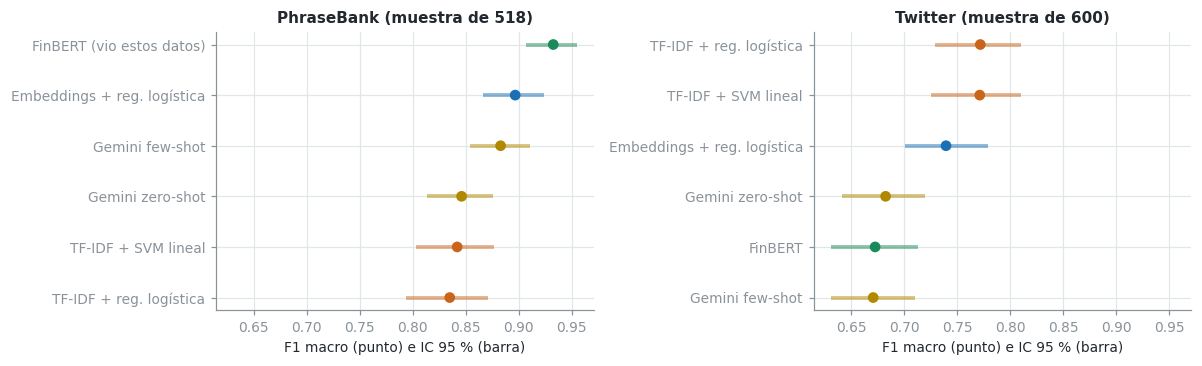

,test,sistema,f1_macro,ic_inf,ic_sup,f1_positivo,f1_negativo,f1_neutro
0,PhraseBank,TF-IDF + reg. logística,0.835,0.793,0.871,0.771,0.821,0.913
1,PhraseBank,TF-IDF + SVM lineal,0.842,0.803,0.877,0.762,0.852,0.912
2,PhraseBank,Embeddings + reg. logística,0.897,0.866,0.924,0.841,0.924,0.925
3,PhraseBank,FinBERT (vio estos datos),0.933,0.907,0.955,0.912,0.931,0.955
4,PhraseBank,Gemini zero-shot,0.846,0.814,0.876,0.773,0.913,0.853
5,PhraseBank,Gemini few-shot,0.883,0.854,0.911,0.838,0.913,0.897
6,Twitter,TF-IDF + reg. logística,0.772,0.729,0.810,0.762,0.663,0.891
7,Twitter,TF-IDF + SVM lineal,0.771,0.725,0.811,0.748,0.671,0.895
8,Twitter,Embeddings + reg. logística,0.739,0.700,0.779,0.710,0.670,0.838
9,Twitter,FinBERT,0.672,0.631,0.713,0.610,0.605,0.802


In [20]:
FINALES = [("TF-IDF + reg. logística", "las dos fuentes"), ("TF-IDF + SVM lineal", "las dos fuentes"),
           ("Embeddings + reg. logística", "las dos fuentes"), ("FinBERT", None),
           ("Gemini zero-shot", "sin entrenamiento (muestra)"), ("Gemini few-shot", "sin entrenamiento (muestra)")]

def pred_de(sistema, entrenamiento, test_nombre):
    if entrenamiento is None:                     # en FinBERT la clave depende del test
        entrenamiento = "de estantería (vio PhraseBank)" if test_nombre == "PhraseBank" else "de estantería"
    return predicciones[(sistema, entrenamiento, test_nombre)]

filas = []
for test_nombre, muestra in MUESTRA_LLM.items():
    y = muestra["etiqueta"].values
    for sistema, entrenamiento in FINALES:
        p = pred_de(sistema, entrenamiento, test_nombre).loc[muestra["id"]].values
        inf, sup = ic_bootstrap(y, p)
        filas.append({"test": test_nombre, "sistema": sistema,
                      "f1_macro": f1_score(y, p, labels=ETIQUETAS, average="macro"), "ic_inf": inf, "ic_sup": sup,
                      **{f"f1_{e}": f for e, f in zip(ETIQUETAS, f1_score(y, p, labels=ETIQUETAS, average=None))}})
comparacion = pd.DataFrame(filas)
comparacion.loc[(comparacion["sistema"] == "FinBERT") & (comparacion["test"] == "PhraseBank"), "sistema"] = "FinBERT (vio estos datos)"

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, (test_nombre, c) in zip(axes, comparacion.groupby("test", sort=False)):
    c = c.sort_values("f1_macro")
    colores = [OCRE if "Gemini" in s else VERDE if "FinBERT" in s else AZUL if "Embeddings" in s else NARANJA
               for s in c["sistema"]]
    y = np.arange(len(c))
    ax.hlines(y, c["ic_inf"], c["ic_sup"], color=colores, lw=2.5, alpha=0.5)
    ax.scatter(c["f1_macro"], y, color=colores, s=36, zorder=3)
    ax.set_yticks(y, c["sistema"])
    ax.set_title(f"{test_nombre} (muestra de {len(MUESTRA_LLM[test_nombre])})")
    ax.set_xlabel("F1 macro (punto) e IC 95 % (barra)")
plt.tight_layout()
plt.savefig(RESULTADOS / "figuras" / "comparacion_f1.png", bbox_inches="tight")
plt.show()

comparacion.round(3)

Los intervalos anteriores son de cada modelo por separado. Para saber si la diferencia entre dos modelos
es real usamos un bootstrap pareado. Remuestreamos los mismos textos para los dos modelos y miramos la
distribución de la diferencia de F1. Si el intervalo de la diferencia no incluye al cero, la diferencia
no se explica por qué textos cayeron en el test.

In [21]:
def bootstrap_pareado(y, pa, pb, n=1000):
    y, pa, pb = map(np.asarray, (y, pa, pb))
    f = lambda yy, pp: f1_score(yy, pp, labels=ETIQUETAS, average="macro", zero_division=0)
    rng = np.random.default_rng(SEMILLA)
    difs = [f(y[i], pa[i]) - f(y[i], pb[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return f(y, pa) - f(y, pb), *np.quantile(difs, [0.025, 0.975])

muestra = MUESTRA_LLM["Twitter"]
y = muestra["etiqueta"].values
p = {s: pred_de(s, e, "Twitter").loc[muestra["id"]].values for s, e in FINALES}
pares = [("Gemini few-shot", "TF-IDF + reg. logística"), ("Gemini few-shot", "Gemini zero-shot"),
         ("Gemini few-shot", "FinBERT"), ("Embeddings + reg. logística", "TF-IDF + reg. logística"),
         ("FinBERT", "TF-IDF + reg. logística")]
pd.DataFrame([{"A": a, "B": b, **dict(zip(["F1(A) - F1(B)", "IC inf", "IC sup"], bootstrap_pareado(y, p[a], p[b])))}
              for a, b in pares]).round(3)

,A,B,F1(A) - F1(B),IC inf,IC sup
0,Gemini few-shot,TF-IDF + reg. logística,-0.101,-0.150,-0.050
1,Gemini few-shot,Gemini zero-shot,-0.012,-0.033,0.009
2,Gemini few-shot,FinBERT,-0.002,-0.046,0.047
3,Embeddings + reg. logística,TF-IDF + reg. logística,-0.032,-0.076,0.015
4,FinBERT,TF-IDF + reg. logística,-0.099,-0.148,-0.052


### En qué se equivocan

Mostramos las matrices de confusión en la muestra del test de Twitter y algunos textos en los que los
modelos no coinciden.

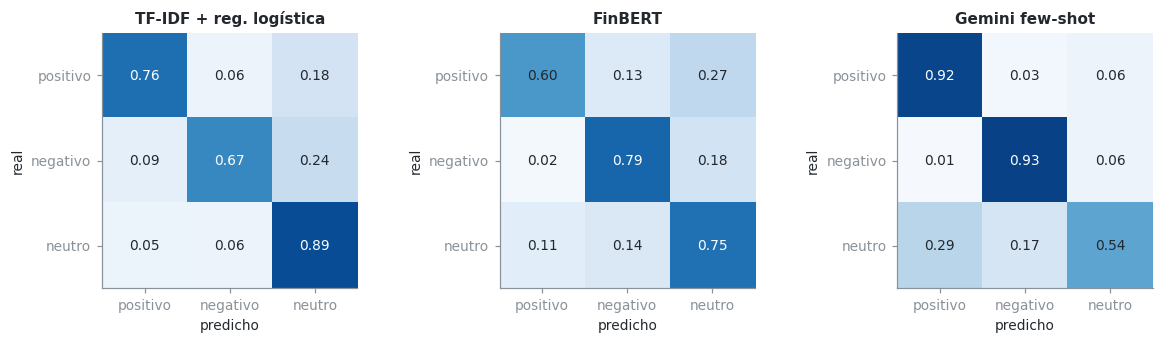

textos en que los tres modelos no coinciden: 300 de 600


,texto,etiqueta,TF-IDF + reg. logística,FinBERT,Gemini few-shot
14317,Chubb to buy stake in China's Huatai Insurance for $1.53 billion #economy #MarketScreener,neutro,neutro,neutro,positivo
14288,"NEW: A federal appeals court in Washington upheld regulations by the FDA saying ""e-cigarettes ar...",neutro,neutro,positivo,negativo
13991,'I can't afford that': Woman in student loan limbo since 1997 decries a muddy system,neutro,neutro,negativo,negativo
14749,$BOXL nice start !!!! $PDSB still accumulating.,positivo,positivo,neutro,positivo
13319,T-Mobile said a hacker gained access to limited information contained in prepaid accounts,negativo,neutro,neutro,negativo
14446,"China Delays Trade Statistics, Merges January and February Data",neutro,negativo,negativo,neutro
14051,Nevada casinos record big Super Bowl win,neutro,positivo,neutro,positivo
14518,Hong Kong Stocks Nearly Recover Post-Holiday Losses With Rally,positivo,positivo,negativo,positivo
14737,Here's Why Zogenix Took a Tumble Today,negativo,negativo,neutro,negativo
13372,$ATGFF - AltaGas declares CAD 0.08 dividend,neutro,neutro,neutro,positivo


In [22]:
mostrar = ["TF-IDF + reg. logística", "FinBERT", "Gemini few-shot"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, s in zip(axes, mostrar):
    m = confusion_matrix(y, p[s], labels=ETIQUETAS, normalize="true")
    ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", color="white" if m[i, j] > 0.6 else TINTA)
    ax.set_xticks(range(3), ETIQUETAS)
    ax.set_yticks(range(3), ETIQUETAS)
    ax.grid(False)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
    ax.set_title(s)
plt.tight_layout()
plt.show()

errores = muestra.assign(**{s: p[s] for s in mostrar})
errores = errores[(errores[mostrar].nunique(axis=1) > 1)]
print(f"textos en que los tres modelos no coinciden: {len(errores)} de {len(muestra)}")
errores[["texto", "etiqueta"] + mostrar].sample(min(10, len(errores)), random_state=3)

Sobre los mismos 600 tuits, TF-IDF queda primero (0,77), seguido por los embeddings (0,74), y más atrás
quedan Gemini zero-shot, FinBERT y Gemini few-shot (entre 0,67 y 0,68). Según el bootstrap pareado,
TF-IDF le gana a Gemini few-shot por 10 puntos, con un intervalo de 5 a 15, y a FinBERT también por 10
puntos, con el mismo intervalo. Las dos diferencias son reales. En cambio, la de embeddings contra
TF-IDF (3 puntos menos, con un intervalo de −8 a +2) y la de Gemini few-shot contra zero-shot no se
distinguen del ruido. En PhraseBank, sin contar a FinBERT, ganan los embeddings (0,897), seguidos por
Gemini few-shot (0,883), con intervalos que se pisan.

Las matrices de confusión explican la diferencia en Twitter. Gemini es el mejor detectando positivos
(92 %) y negativos (93 %), pero solo deja como neutros al 54 % de los neutros y al 29 % los llama
positivos. Los ejemplos de desacuerdo muestran el motivo. *"Chubb to buy stake in China's Huatai
Insurance for $1.53 billion"* y *"AltaGas declares CAD 0.08 dividend"* son neutros en el dataset, y
Gemini los clasifica como positivos.

En Twitter, los anotadores marcaron las compras y los dividendos como neutros, y nuestro prompt dice
literalmente que los *deals* son positivos. Los modelos supervisados aprenden la convención de
etiquetado del dataset a partir de 8.000 ejemplos. El LLM, en cambio, sigue la definición que le dimos,
y 9 ejemplos no alcanzan para transmitir esa convención. Parte del error de Gemini es un desacuerdo con
el criterio de los anotadores y no una incapacidad de entender el texto.

En la mitad de la muestra (300 de 600 textos) al menos uno de los tres modelos no coincide con los
otros dos.

In [23]:
pd.DataFrame(resultados).to_csv(RESULTADOS / "tabla_clasificacion_completa.csv", index=False)
comparacion.to_csv(RESULTADOS / "tabla_comparacion_muestra.csv", index=False)
tabla_dominio(["TF-IDF + reg. logística", "TF-IDF + SVM lineal", "Embeddings + reg. logística"]).to_csv(
    RESULTADOS / "tabla_cambio_de_dominio.csv")

## 8. Noticias reales y precios

### 8.1 Recolección de titulares

Elegimos 8 acciones muy negociadas y con mucha cobertura de prensa, para tener noticias todos los días.
Son Apple, Microsoft, Nvidia, Tesla, Amazon, Meta, Alphabet y JPMorgan. Juntamos los titulares en inglés
de los últimos 90 días desde el buscador RSS de Google News. Cada consulta devuelve hasta 100
resultados, así que buscamos semana por semana con los operadores `after:` y `before:`, una vez por el
nombre de la empresa y otra por el ticker. Cada titular viene con el medio y la fecha y hora de
publicación.

Estos titulares no tienen etiqueta, porque no sabemos cuál es su sentimiento verdadero. Los vamos a
evaluar contra el precio.

In [24]:
import requests
import xml.etree.ElementTree as ET
from email.utils import parsedate_to_datetime
from urllib.parse import quote

ACTIVOS = {"AAPL": ["Apple"], "MSFT": ["Microsoft"], "NVDA": ["Nvidia", "NVIDIA"], "TSLA": ["Tesla"],
           "AMZN": ["Amazon"], "META": ["Meta", "Facebook"], "GOOGL": ["Alphabet", "Google"],
           "JPM": ["JPMorgan", "JP Morgan"]}
MERCADO = "SPY"     # ETF del S&P 500, la referencia de "el mercado"
RSS = "https://news.google.com/rss/search?q={q}&hl=en-US&gl=US&ceid=US:en"

def buscar_google_news(consulta):
    try:
        r = requests.get(RSS.format(q=quote(consulta)), timeout=20, headers={"User-Agent": "Mozilla/5.0"})
        items = ET.fromstring(r.content).iter("item")
    except Exception as e:
        print("  aviso:", str(e)[:80])
        return []
    filas = []
    for item in items:
        titular, medio = item.findtext("title", ""), item.findtext("source", "")
        if medio and titular.endswith(f" - {medio}"):       # Google agrega " - Medio" al final del titular
            titular = titular[: -len(medio) - 3]
        try:
            fecha = parsedate_to_datetime(item.findtext("pubDate", "")).astimezone(timezone.utc)
        except Exception:
            continue
        filas.append({"titular": titular, "publicada_utc": fecha, "medio": medio, "url": item.findtext("link", "")})
    return filas

def recolectar(dias=90, ventana=7):
    hasta, filas = datetime.now(timezone.utc), []
    for ticker, nombres in ACTIVOS.items():
        n0 = len(filas)
        for ini in range(0, dias, ventana):
            fin = hasta - timedelta(days=ini)
            desde = fin - timedelta(days=ventana)
            rango = f" after:{desde:%Y-%m-%d} before:{fin + timedelta(days=1):%Y-%m-%d}"
            for termino in [nombres[0], ticker]:
                filas += [{"ticker": ticker, **f, "fuente": "google_news"}
                          for f in buscar_google_news(f'"{termino}" stock{rango}')]
                time.sleep(0.5)
        print(f"  {ticker}: {len(filas) - n0} titulares")
    return pd.DataFrame(filas)

if not (DATOS / "noticias_crudas.csv").exists():
    recolectar().to_csv(DATOS / "noticias_crudas.csv", index=False)
crudas = pd.read_csv(DATOS / "noticias_crudas.csv")
print(f"{len(crudas)} titulares crudos, del {crudas['publicada_utc'].min()[:10]} al {crudas['publicada_utc'].max()[:10]}")

  AAPL: 1788 titulares
  MSFT: 1692 titulares
  NVDA: 1780 titulares
  TSLA: 1840 titulares
  AMZN: 1756 titulares
  META: 1851 titulares
  GOOGL: 1508 titulares
  JPM: 1351 titulares
13566 titulares crudos, del 2026-07-31 al 2026-10-30


### 8.2 Limpieza

1. Nos quedamos con los titulares de 5 a 30 palabras, para dejar afuera los cortados y los que son listas.
2. El titular tiene que nombrar a la empresa o a su ticker. La búsqueda a veces devuelve notas en las que
   la empresa aparece solo en el cuerpo, y en esos casos el titular no habla de ella.
3. El mismo titular publicado por varios medios cuenta una sola vez por acción, y nos quedamos con la
   primera publicación.
4. Marcamos los titulares que describen un movimiento de precio, como *"Tesla shares fall 5%"* o
   *"Nvidia stock jumps"*. Estos titulares no anticipan nada, sino que cuentan lo que ya pasó. Su relación
   con el precio del mismo día es casi tautológica, así que en la sección 9 los analizamos por separado.

In [25]:
RE_PRECIO = re.compile(
    r"\b(shares?|stocks?|stock price|market cap)\b.{0,40}\b(rise[sn]?|rose|jump(s|ed)?|soar(s|ed)?|surge[sd]?|"
    r"rall(y|ies|ied)|gain(s|ed)?|climb(s|ed)?|fall(s|en)?|fell|drop(s|ped)?|slump(s|ed)?|tumble[sd]?|"
    r"plunge[sd]?|slide[sd]?|sink(s)?|sank|dip(s|ped)?|up|down)\b|\b\d+(\.\d+)?\s?%",
    re.IGNORECASE)

def menciona(titular, ticker):
    patrones = [re.escape(n) for n in ACTIVOS[ticker]] + [rf"\$?{ticker}\b"]
    return re.search(r"\b(" + "|".join(patrones) + r")", titular, re.IGNORECASE) is not None

nots = crudas.copy()
nots["titular"] = nots["titular"].astype(str).str.strip()
nots["publicada_utc"] = pd.to_datetime(nots["publicada_utc"], utc=True)
pasos = {"crudos": len(nots)}
nots = nots[nots["titular"].str.split().str.len().between(5, 30)]
pasos["5 a 30 palabras"] = len(nots)
nots = nots[[menciona(t, k) for t, k in zip(nots["titular"], nots["ticker"])]]
pasos["nombran a la empresa"] = len(nots)
nots["_norm"] = nots["titular"].str.lower().str.replace(r"[^\w\s]", "", regex=True).str.strip()
nots = nots.sort_values("publicada_utc").drop_duplicates(["_norm", "ticker"]).drop(columns="_norm")
pasos["sin repetidos"] = len(nots)
nots["describe_precio"] = nots["titular"].str.contains(RE_PRECIO)
nots = nots.reset_index(drop=True)
nots.insert(0, "id", [f"no_{i:05d}" for i in range(len(nots))])

display(pd.Series(pasos, name="titulares").to_frame())
print(f"describen un movimiento de precio: {nots['describe_precio'].mean():.0%}")
nots.groupby("ticker").agg(titulares=("id", "size"), describen_precio=("describe_precio", "mean")).round(2).T

,titulares
crudos,13566
5 a 30 palabras,13499
nombran a la empresa,12818
sin repetidos,9079


describen un movimiento de precio: 22%


ticker,AAPL,AMZN,GOOGL,JPM,META,MSFT,NVDA,TSLA
titulares,1253.00,1146.00,1036.00,981.00,1118.00,1022.00,1217.00,1306.00
describen_precio,0.16,0.22,0.23,0.19,0.25,0.21,0.19,0.26


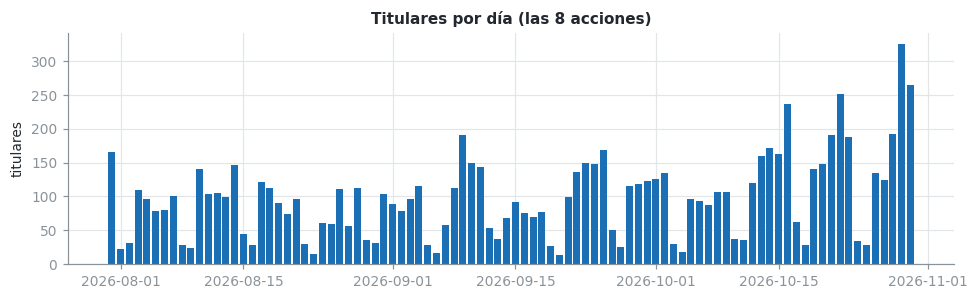

AMZN  2026-10-25 15:42  The Hidden $496 Billion Catalyst Waiting to Ignite Amazon Stock on Oct. 29
GOOGL 2026-09-22 07:00  Not Micron. Not Alphabet. Here's My Top Artificial Intelligence (AI) Stock Pick for the Next 3 Years.
AAPL  2026-08-18 07:00  Billionaire David Tepper Is Short Apple And Even Bet Against Buffett's Berkshire Hathaway. What Does He See?
JPM   2026-08-31 07:00  [precio] Ather Energy Stock Climbs Nearly 4% On JPMorgan Target Hike, Konarc Launch
TSLA  2026-10-17 07:00  Cathie Wood-Led Ark Invest's Biggest Q3 Winners and Losers — PLTR, NVDA, TXG Led While TSLA, RKLB Dragged
MSFT  2026-09-01 07:00  [precio] Microsoft Stock Hasn’t Done Much This Year. Why Azure Growth Means the Stock Has 19% Upside.
AAPL  2026-10-22 17:02  Apple (AAPL) Stands Out Amid AI Market Volatility
NVDA  2026-08-06 07:00  NVDA Reportedly Weighs Lower-Memory Rubin Ultra GPU Designs To Ease HBM Bottleneck — Why Retail Is Watching Mi


In [26]:
fig, ax = plt.subplots(figsize=(9, 2.8))
por_dia = nots.groupby(nots["publicada_utc"].dt.date).size()
ax.bar(por_dia.index, por_dia.values, color=AZUL, width=0.8)
ax.set_ylabel("titulares")
ax.set_title("Titulares por día (las 8 acciones)")
plt.tight_layout()
plt.show()

for _, r in nots.sample(8, random_state=3).iterrows():
    print(f"{r['ticker']:5s} {str(r['publicada_utc'])[:16]}  {'[precio] ' if r['describe_precio'] else ''}{r['titular'][:110]}")

De 13.566 titulares crudos quedan 9.079. El recorte grande es por repetidos, ya que el 29 % de los que
nombran a la empresa eran el mismo titular en varios medios o en las dos búsquedas (por nombre y por
ticker). Quedan entre 981 (JPMorgan) y 1.306 (Tesla) titulares por acción. El 22 % describe un
movimiento de precio, desde el 16 % en Apple hasta el 26 % en Tesla. El gráfico por día muestra el ritmo
semanal, con pocos titulares los fines de semana.

Los ejemplos también muestran ruido que la limpieza no elimina. *"Ather Energy Stock Climbs Nearly 4% On
JPMorgan Target Hike"* queda asignado a JPMorgan, pero habla de otra empresa, y *"Not Micron. Not
Alphabet. Here's My Top AI Stock Pick"* nombra a Alphabet sin ser sobre Alphabet. Además, 6 de los 8
ejemplos tienen como hora las 07:00 UTC, que es la medianoche de California. Para muchos titulares Google
News informa solo la fecha y no la hora, algo que retomamos en las limitaciones.

### 8.3 Precios y retornos alrededor de cada noticia

Bajamos de Yahoo Finance los cierres diarios ajustados por dividendos y splits de las 8 acciones y de
SPY, el ETF del S&P 500.

**Día del evento.** Para cada titular buscamos el primer cierre de mercado posterior a la publicación.
La bolsa de Nueva York cierra a las 16:00, hora de Nueva York. Una noticia publicada un martes a las
10:00 tiene como día del evento ese martes, y una publicada el martes a las 17:00 o el sábado tiene como
día del evento el día hábil siguiente.

**Tres ventanas.** Usamos cierres de días hábiles, con d0 como día del evento.

| Ventana | Desde | Hasta | Para qué sirve |
|---|---|---|---|
| previa | cierre d0−2 | cierre d0−1 | ver si la noticia llega después de que el precio ya se movió |
| evento | cierre d0−1 | cierre d0 | medir la reacción del mismo día, que incluye el momento de la publicación |
| siguiente | cierre d0 | cierre d0+1 | la ventana del plan, que empieza después de publicada la noticia |

**Retorno anormal.** Es el retorno de la acción menos el retorno de SPY en la misma ventana. Así, un día
en que sube toda la bolsa no se le atribuye a la noticia.

73 ruedas, del 2026-07-21 al 2026-10-30


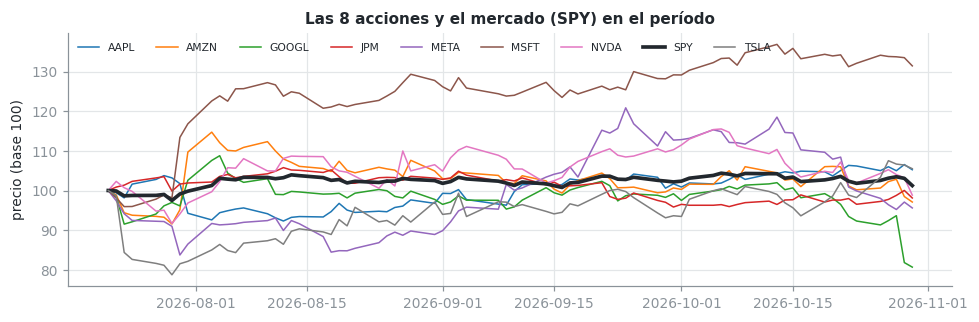

In [27]:
import yfinance as yf

if not (DATOS / "precios.csv").exists():
    inicio = (nots["publicada_utc"].min() - pd.Timedelta(days=10)).strftime("%Y-%m-%d")
    fin = (pd.Timestamp.now() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    cierres = yf.download(list(ACTIVOS) + [MERCADO], start=inicio, end=fin, auto_adjust=True, progress=False)["Close"]
    cierres.index = pd.to_datetime(cierres.index).tz_localize(None).normalize()
    cierres.dropna(how="all").to_csv(DATOS / "precios.csv")
precios = pd.read_csv(DATOS / "precios.csv", index_col=0, parse_dates=True)
print(f"{len(precios)} ruedas, del {precios.index.min():%Y-%m-%d} al {precios.index.max():%Y-%m-%d}")

fig, ax = plt.subplots(figsize=(9, 3))
for tk in precios.columns:
    serie = precios[tk] / precios[tk].dropna().iloc[0] * 100
    ax.plot(serie, lw=2.4 if tk == MERCADO else 1, color=TINTA if tk == MERCADO else None, label=tk)
ax.set_ylabel("precio (base 100)")
ax.set_title("Las 8 acciones y el mercado (SPY) en el período")
ax.legend(ncol=9, fontsize=7, frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

In [28]:
VENTANAS = {"previa": (-2, -1), "evento": (-1, 0), "siguiente": (0, 1)}

def dia_evento(publicada_utc, ruedas):
    # posición (en la lista de ruedas) del primer cierre posterior a la publicación
    t = pd.to_datetime(publicada_utc, utc=True).dt.tz_convert("America/New_York")
    fecha = t.dt.tz_localize(None).dt.normalize()
    pos = ruedas.searchsorted(fecha.values, side="left")          # primera rueda >= fecha
    es_rueda = (pos < len(ruedas)) & (ruedas[np.minimum(pos, len(ruedas) - 1)] == fecha.values)
    pos = np.where(es_rueda & (t.dt.hour >= 16).values, pos + 1, pos)   # después del cierre pasa a la rueda siguiente
    return np.where(pos < len(ruedas), pos, -1)

ruedas = precios.index
d0 = dia_evento(nots["publicada_utc"], ruedas)
ret = nots[["id", "ticker"]].copy()
ret["dia_evento"] = [ruedas[i].date() if i >= 0 else None for i in d0]
for nombre, (a, b) in VENTANAS.items():
    anormal = []
    for i, tk in zip(d0, nots["ticker"]):
        if i < 0 or i + a < 0 or i + b >= len(ruedas):
            anormal.append(np.nan)                # la ventana cae fuera de los datos (p. ej. noticias de hoy)
            continue
        r_accion = precios[tk].iloc[i + b] / precios[tk].iloc[i + a] - 1
        r_mercado = precios[MERCADO].iloc[i + b] / precios[MERCADO].iloc[i + a] - 1
        anormal.append(r_accion - r_mercado)
    ret[f"anormal_{nombre}"] = anormal

print("noticias con retorno en la ventana siguiente:", ret["anormal_siguiente"].notna().sum())
ejemplo = nots.join(ret[["dia_evento"] + [f"anormal_{v}" for v in VENTANAS]]).dropna().iloc[0]
print(f"\nejemplo: {ejemplo['ticker']} · publicada {ejemplo['publicada_utc']:%a %Y-%m-%d %H:%M} UTC · día del evento {ejemplo['dia_evento']}")
print("  ", ejemplo["titular"])
print("   retornos anormales (pb):", {v: round(ejemplo[f'anormal_{v}'] * 1e4, 1) for v in VENTANAS})
(ret[[f"anormal_{v}" for v in VENTANAS]] * 1e4).describe().round(1)

noticias con retorno en la ventana siguiente: 8735

ejemplo: AAPL · publicada Fri 2026-07-31 07:00 UTC · día del evento 2026-07-31
   Apple slides on Q3 results, guidance; GF Securities downgrades (AAPL:NASDAQ)
   retornos anormales (pb): {'previa': np.float64(-308.4), 'evento': np.float64(-807.4), 'siguiente': np.float64(-320.2)}


,anormal_previa,anormal_evento,anormal_siguiente
count,9051.0,9051.0,8735.0
mean,4.3,-4.4,-3.1
std,226.1,255.4,172.9
min,-1225.9,-1225.9,-1225.9
25%,-88.4,-102.3,-92.6
50%,-4.7,-3.9,-7.7
75%,100.0,95.9,81.6
max,1460.1,1460.1,808.3


Los retornos están expresados en puntos básicos (pb), donde 100 pb equivalen a 1 %.

De los 9.079 titulares, 8.735 tienen retorno en la ventana siguiente, porque a los de los últimos días
todavía les falta el día siguiente. Los retornos anormales están centrados en cero y varían mucho, con un
desvío diario de entre 173 y 255 pb según la ventana. El ejemplo de Apple, con resultados del tercer
trimestre y una rebaja de recomendación, muestra un día del evento con 807 pb por debajo del mercado.

### 8.4 Clasificación de los titulares

Clasificamos todos los titulares con los modelos entrenados con las dos fuentes y con FinBERT. Gemini
clasifica en zero-shot una muestra de 1.500 titulares estratificada por acción, de nuevo por el límite
del plan gratuito, y en este caso le indicamos de qué acción habla cada titular.

Como acá no hay etiquetas, lo primero que podemos mirar es cuánto coinciden los modelos entre sí. Usamos
el kappa de Cohen, que mide el acuerdo descontando el que se daría por azar. Vale 0 cuando el acuerdo es
el esperable por azar y 1 cuando es perfecto.

In [29]:
pred = nots.copy()
for nombre in ["TF-IDF + reg. logística", "TF-IDF + SVM lineal"]:
    vec, modelo = modelos_finales[nombre]
    pred[nombre] = modelo.predict(vec.transform(pred["titular"]))
pred["Embeddings + reg. logística"] = modelos_finales["Embeddings + reg. logística"][1].predict(
    embeddings(pred["titular"], "noticias"))
pred["FinBERT"] = predecir_finbert(pred["titular"])

frac = min(1.0, 1500 / len(nots))
m = nots.groupby("ticker").sample(frac=frac, random_state=SEMILLA)
etiquetas_llm, _ = clasificar_llm(m["titular"].tolist(), "gemini_zero__noticias", tickers=m["ticker"].tolist())
pred = pred.merge(m[["id"]].assign(**{"Gemini zero-shot": etiquetas_llm}), on="id", how="left")
pred.to_csv(RESULTADOS / "noticias_predicciones.csv", index=False)

SISTEMAS = ["TF-IDF + reg. logística", "TF-IDF + SVM lineal", "Embeddings + reg. logística", "FinBERT", "Gemini zero-shot"]
display(pd.DataFrame({s: pred[s].value_counts(normalize=True) for s in SISTEMAS}).loc[ETIQUETAS].round(2))

  aviso: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing  -> espero 20 s
  gemini_zero__noticias: 1500 textos · 60 consultas nuevas · 0 sin respuesta válida


,TF-IDF + reg. logística,TF-IDF + SVM lineal,Embeddings + reg. logística,FinBERT,Gemini zero-shot
positivo,0.30,0.29,0.35,0.23,0.45
negativo,0.18,0.17,0.26,0.23,0.22
neutro,0.51,0.54,0.39,0.54,0.33


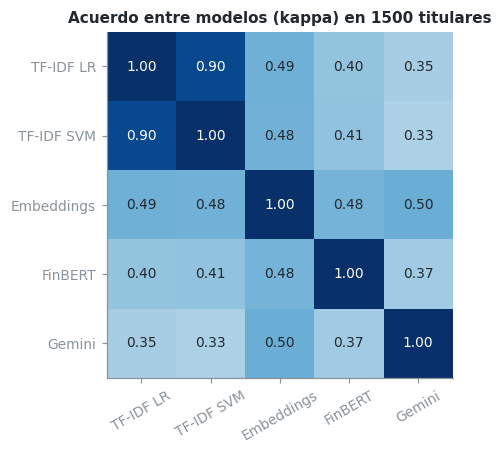

In [30]:
from sklearn.metrics import cohen_kappa_score

con_llm = pred.dropna(subset=["Gemini zero-shot"])
kappa = pd.DataFrame(np.eye(len(SISTEMAS)), index=SISTEMAS, columns=SISTEMAS)
for a, b in combinations(SISTEMAS, 2):
    kappa.loc[a, b] = kappa.loc[b, a] = cohen_kappa_score(con_llm[a], con_llm[b])

fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.imshow(kappa.values, cmap="Blues", vmin=0, vmax=1)
for i in range(len(SISTEMAS)):
    for j in range(len(SISTEMAS)):
        ax.text(j, i, f"{kappa.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if kappa.iloc[i, j] > 0.6 else TINTA)
cortos = ["TF-IDF LR", "TF-IDF SVM", "Embeddings", "FinBERT", "Gemini"]
ax.set_xticks(range(len(SISTEMAS)), cortos, rotation=30)
ax.set_yticks(range(len(SISTEMAS)), cortos)
ax.grid(False)
ax.set_title(f"Acuerdo entre modelos (kappa) en {len(con_llm)} titulares")
plt.tight_layout()
plt.show()

Los dos TF-IDF coinciden casi siempre (κ = 0,90), porque usan la misma representación. Entre familias
distintas el acuerdo es solo moderado, con κ entre 0,33 y 0,50, bastante menos de lo que sugieren los
tests etiquetados. Ningún modelo se entrenó con titulares de 2026 y cada uno generaliza a su manera.
Gemini es el más tajante, porque llama positivos al 45 % de los titulares y neutros solo al 33 %, contra
51 % a 54 % de neutros en TF-IDF y FinBERT. Sin etiquetas no podemos decir cuál tiene razón, y por eso la
referencia para evaluar es el precio.

## 9. Relación entre la señal de texto y el precio

La miramos de tres maneras, para cada modelo y cada ventana.

1. **Por titular.** Calculamos el retorno anormal promedio de los titulares que el modelo clasificó como
   positivos, negativos y neutros, con su intervalo de confianza por bootstrap. Si la señal sirve, los
   positivos deberían tener retornos mayores que los negativos, y lo resumimos con la diferencia entre
   positivos y negativos.
2. **Por acción y día.** Varios titulares de la misma acción en el mismo día no son observaciones
   independientes, porque comparten el mismo retorno. Por eso armamos un puntaje diario con el promedio
   de los signos de sus titulares (+1 positivo, 0 neutro, −1 negativo) y medimos la correlación de
   Spearman con el retorno anormal del día. Usamos Spearman, que trabaja con rangos, porque los retornos
   tienen colas pesadas y unos pocos días extremos dominarían una correlación de Pearson.
3. **Dirección.** En los días con puntaje distinto de cero contamos qué proporción de las veces se acierta
   el signo del retorno anormal, y lo comparamos con el 50 % de una moneda mediante una prueba binomial.

Todo se calcula también sin los titulares que describen el precio, porque esos titulares inflan la
relación en la ventana del evento sin aportar ninguna anticipación.

In [31]:
from scipy.stats import spearmanr, binomtest

SIGNO = {"positivo": 1, "negativo": -1, "neutro": 0}
base = pred.merge(ret, on=["id", "ticker"])

def media_con_ic(x, n=1000):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    rng = np.random.default_rng(SEMILLA)
    medias = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)]
    return x.mean(), *np.quantile(medias, [0.025, 0.975])

def analizar(datos, sistema, ventana):
    datos = datos.dropna(subset=[sistema])
    fila = {"sistema": sistema, "ventana": ventana}
    pos = datos.loc[datos[sistema] == "positivo", f"anormal_{ventana}"].dropna().values
    neg = datos.loc[datos[sistema] == "negativo", f"anormal_{ventana}"].dropna().values
    rng = np.random.default_rng(SEMILLA)
    difs = [rng.choice(pos, len(pos)).mean() - rng.choice(neg, len(neg)).mean() for _ in range(1000)]
    fila["pos - neg (pb)"] = (pos.mean() - neg.mean()) * 1e4
    fila["IC inf"], fila["IC sup"] = np.quantile(difs, [0.025, 0.975]) * 1e4
    # puntaje diario por acción
    dias = (datos.assign(signo=datos[sistema].map(SIGNO)).dropna(subset=["dia_evento", f"anormal_{ventana}"])
            .groupby(["ticker", "dia_evento"]).agg(puntaje=("signo", "mean"), retorno=(f"anormal_{ventana}", "first")))
    rho, p_rho = spearmanr(dias["puntaje"], dias["retorno"])
    con_senal = dias[dias["puntaje"] != 0]
    aciertos = int((np.sign(con_senal["puntaje"]) == np.sign(con_senal["retorno"])).sum())
    fila.update({"spearman": rho, "p": p_rho, "días": len(dias),
                 "acierto dirección": aciertos / len(con_senal),
                 "p binomial": binomtest(aciertos, len(con_senal), 0.5, alternative="greater").pvalue})
    return fila

GRUPOS = {"todas": base, "sin las que describen el precio": base[~base["describe_precio"]],
          "solo las que describen el precio": base[base["describe_precio"]]}
senal = pd.DataFrame([{"grupo": g, **analizar(datos, s, v)}
                      for g, datos in GRUPOS.items() for s in SISTEMAS for v in VENTANAS])
senal.to_csv(RESULTADOS / "tabla_senal_precio.csv", index=False)
senal.query("grupo == 'todas'").drop(columns="grupo").round(3)

,sistema,ventana,pos - neg (pb),IC inf,IC sup,spearman,p,días,acierto dirección,p binomial
0,TF-IDF + reg. logística,previa,54.663,39.847,69.128,0.169,0.000,518,0.553,0.014
1,TF-IDF + reg. logística,evento,142.222,126.137,158.934,0.362,0.000,518,0.599,0.000
2,TF-IDF + reg. logística,siguiente,-14.736,-25.316,-3.683,-0.035,0.428,510,0.487,0.731
3,TF-IDF + SVM lineal,previa,61.213,45.243,77.340,0.180,0.000,518,0.534,0.079
4,TF-IDF + SVM lineal,evento,153.899,136.310,171.512,0.374,0.000,518,0.603,0.000
5,TF-IDF + SVM lineal,siguiente,-17.132,-28.653,-6.340,-0.059,0.180,510,0.485,0.747
6,Embeddings + reg. logística,previa,65.018,52.118,77.163,0.215,0.000,518,0.589,0.000
7,Embeddings + reg. logística,evento,139.160,122.946,154.865,0.439,0.000,518,0.642,0.000
8,Embeddings + reg. logística,siguiente,-20.052,-29.449,-11.277,-0.128,0.004,510,0.442,0.994
9,FinBERT,previa,74.795,59.607,88.411,0.250,0.000,518,0.604,0.000


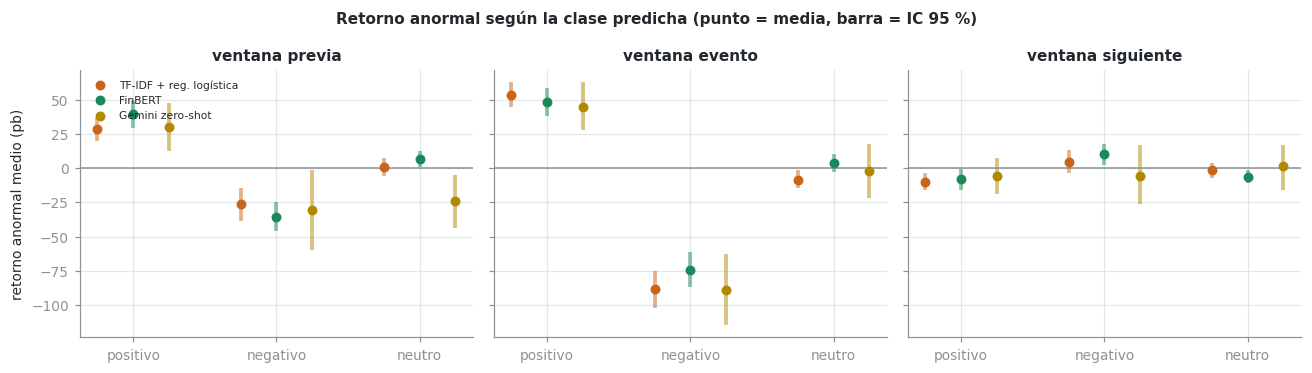

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, ventana in zip(axes, VENTANAS):
    for k, (s, color) in enumerate(zip(["TF-IDF + reg. logística", "FinBERT", "Gemini zero-shot"], [NARANJA, VERDE, OCRE])):
        datos = base.dropna(subset=[s])
        for j, clase in enumerate(ETIQUETAS):
            media, inf, sup = media_con_ic(datos.loc[datos[s] == clase, f"anormal_{ventana}"])
            x = j + (k - 1) * 0.25
            ax.vlines(x, inf * 1e4, sup * 1e4, color=color, lw=2.5, alpha=0.5)
            ax.scatter(x, media * 1e4, color=color, s=30, zorder=3, label=s if j == 0 else None)
    ax.axhline(0, color=TENUE, lw=1)
    ax.set_xticks(range(3), ETIQUETAS)
    ax.set_title(f"ventana {ventana}")
axes[0].set_ylabel("retorno anormal medio (pb)")
axes[0].legend(frameon=False, fontsize=7, loc="upper left")
plt.suptitle("Retorno anormal según la clase predicha (punto = media, barra = IC 95 %)", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTADOS / "figuras" / "senal_precio.png", bbox_inches="tight")
plt.show()

El patrón es el mismo en los cinco modelos y en las tres formas de medirlo.

- **Ventana evento.** El día de la noticia la relación es fuerte. Los titulares positivos tienen un
  retorno anormal entre 122 y 154 pb mayor que los negativos, la correlación de Spearman del puntaje
  diario va de 0,28 a 0,44 y el signo del día se acierta entre el 60 % y el 64 % de las veces (p < 0,001).
- **Ventana previa.** El día anterior a la noticia también hay relación, de 55 a 75 pb, con correlaciones
  de 0,14 a 0,25. Muchos titulares se escriben después de que el precio se movió, porque los medios
  cuentan las subas y las bajas.
- **Ventana siguiente.** Después de publicada la noticia no hay relación positiva. La diferencia entre
  positivos y negativos es levemente negativa, de entre 15 y 20 pb, y su intervalo no incluye al cero en
  cuatro de los cinco modelos. Las correlaciones van de −0,13 a 0,02 y el acierto de dirección no pasa
  del 49 %.

El sentimiento de los titulares acompaña y sigue al precio, pero no lo anticipa. La pequeña reversión del
día siguiente va en la línea de lo que encontró Tetlock (2007), que observó que el pesimismo de la prensa
viene con presión bajista y después con una reversión parcial. De todas formas es un efecto chico, de 15
a 20 pb frente a un desvío diario de 173 pb.

In [33]:
print("Sin los titulares que describen el precio")
display(senal.query("grupo == 'sin las que describen el precio'").drop(columns="grupo").round(3))
print("Solo los titulares que describen el precio")
display(senal.query("grupo == 'solo las que describen el precio'").drop(columns="grupo").round(3))

Sin los titulares que describen el precio


,sistema,ventana,pos - neg (pb),IC inf,IC sup,spearman,p,días,acierto dirección,p binomial
15,TF-IDF + reg. logística,previa,33.949,16.820,51.801,0.100,0.024,515,0.523,0.190
16,TF-IDF + reg. logística,evento,66.564,48.474,83.094,0.189,0.000,515,0.546,0.032
17,TF-IDF + reg. logística,siguiente,-6.487,-19.567,6.283,-0.008,0.851,507,0.504,0.461
18,TF-IDF + SVM lineal,previa,41.292,23.100,60.998,0.109,0.013,515,0.506,0.422
19,TF-IDF + SVM lineal,evento,72.953,54.886,93.741,0.172,0.000,515,0.540,0.058
20,TF-IDF + SVM lineal,siguiente,-11.182,-23.433,2.074,-0.042,0.344,507,0.491,0.654
21,Embeddings + reg. logística,previa,52.248,35.575,67.675,0.171,0.000,515,0.564,0.004
22,Embeddings + reg. logística,evento,70.245,53.400,84.938,0.266,0.000,515,0.573,0.001
23,Embeddings + reg. logística,siguiente,-16.861,-27.349,-6.273,-0.099,0.026,507,0.459,0.961
24,FinBERT,previa,65.887,46.939,82.845,0.197,0.000,515,0.588,0.000


Solo los titulares que describen el precio


,sistema,ventana,pos - neg (pb),IC inf,IC sup,spearman,p,días,acierto dirección,p binomial
30,TF-IDF + reg. logística,previa,90.482,64.663,117.141,0.163,0.000,454,0.558,0.014
31,TF-IDF + reg. logística,evento,273.041,242.705,306.884,0.384,0.000,454,0.662,0.000
32,TF-IDF + reg. logística,siguiente,-29.095,-49.197,-10.289,-0.052,0.271,446,0.457,0.956
33,TF-IDF + SVM lineal,previa,92.999,65.993,119.307,0.165,0.000,454,0.553,0.022
34,TF-IDF + SVM lineal,evento,283.193,250.359,317.822,0.403,0.000,454,0.664,0.000
35,TF-IDF + SVM lineal,siguiente,-26.700,-46.106,-7.502,-0.044,0.355,446,0.446,0.984
36,Embeddings + reg. logística,previa,92.054,67.246,116.177,0.179,0.000,454,0.586,0.000
37,Embeddings + reg. logística,evento,285.743,258.455,318.071,0.443,0.000,454,0.694,0.000
38,Embeddings + reg. logística,siguiente,-26.613,-43.718,-7.855,-0.066,0.163,446,0.450,0.979
39,FinBERT,previa,89.535,66.043,113.865,0.193,0.000,454,0.582,0.001


Sacar los titulares que describen el precio cambia mucho la ventana evento. La diferencia cae a la mitad
(en TF-IDF pasa de 142 a 67 pb y la correlación de 0,36 a 0,19), así que parte de la señal venía de
titulares que narraban el movimiento. Lo que queda sigue siendo significativo, pero dentro del mismo día
no podemos separar causa y efecto. La noticia pudo mover el precio, o el precio pudo motivar la nota.

En la ventana siguiente, sin esos titulares, el intervalo de la diferencia incluye al cero en cuatro de
los cinco modelos y el acierto de dirección queda entre 46 % y 50 %. La excepción son los embeddings, con
17 pb menos y un intervalo de −27 a −6. Con solo los titulares de precio, la ventana evento muestra lo
esperable de una relación casi tautológica, con entre 226 y 286 pb de diferencia y entre 65 % y 69 % de
acierto.

Entre modelos, ventanas y grupos hicimos 45 comparaciones. Con un nivel del 5 %, es esperable que algunos
resultados aislados salgan significativos por azar. Lo que pesa es que el patrón (evento fuerte, previa
positiva y siguiente nula) se repite en todos los modelos.

## 10. Conclusiones

1. Se puede clasificar el sentimiento de noticias financieras sin etiquetar a mano, usando datasets
   públicos. Obtuvimos un F1 macro de 0,77 en tuits de mercado y cercano a 0,90 en oraciones de noticias,
   sin contar a FinBERT en PhraseBank.
2. El baseline clásico es difícil de superar dentro de su dominio. Con 8.000 ejemplos de Twitter, TF-IDF le
   gana a FinBERT y a Gemini con diferencias significativas, empata con los embeddings y es más de 100
   veces más barato que el LLM.
3. El problema de fondo es el cambio de dominio. TF-IDF se derrumba cuando cambia el estilo del texto (de
   0,76 a 0,44), mientras que los embeddings y FinBERT transfieren mucho mejor (0,66 y 0,67). El LLM no
   necesita entrenamiento, pero aplica la definición del prompt y no la convención de los anotadores, y
   eso explica buena parte de su desempeño en Twitter.
4. En los titulares reales los modelos coinciden poco (κ entre 0,33 y 0,50), así que la elección del
   modelo cambia la señal que se obtiene.
5. Respondiendo a la pregunta del trabajo, la señal de texto se relaciona fuertemente con el precio del
   mismo día y del día anterior, y no con el de la ventana siguiente, en ninguno de los cinco modelos. Para
   estas 8 acciones grandes, la información de los titulares ya está en el precio cuando sale la noticia.
   Es lo esperable en acciones tan seguidas por el mercado, y muestra que usar el precio como referencia, y
   no como objetivo del modelo, fue una buena forma de acotar el trabajo.

### Limitaciones

- **Hora de publicación.** Para muchos titulares Google News informa solo la fecha, con hora 07:00 UTC. Si
  alguna de esas noticias salió después del cierre, la asignamos al día anterior al correcto. En ese caso
  su reacción caería en nuestra ventana siguiente y empujaría a encontrar una relación positiva ahí, que no
  aparece. Aun así, con datos diarios no podemos separar qué pasó antes y qué después de la noticia dentro
  del mismo día, y para eso harían falta precios intradiarios.
- **Asignación de titulares.** Que un titular nombre a la empresa no garantiza que hable de ella, como en el
  caso de Ather Energy y JPMorgan.
- **Alcance.** Trabajamos con 8 acciones muy grandes durante 90 días, lo que da unos 510 pares de acción y
  día. Son las acciones más eficientes del mercado, y en empresas chicas, con menos cobertura, el resultado
  podría ser distinto.
- **Etiquetas de otro dominio.** Los datasets son de otras épocas y estilos (noticias de empresas
  finlandesas de los años 2000 y tuits de 2019 y 2020) y tienen sus propias convenciones de etiquetado. Por
  diseño no etiquetamos titulares de 2026, así que no podemos medir la exactitud real en ese dominio.
- **LLM.** Por el límite del plan gratuito usamos un modelo liviano (Flash-Lite) y muestras de 600 y 1.500
  textos. Un modelo más grande, o un prompt que siga la convención de Twitter, podría rendir distinto.
- **Comparaciones múltiples y grilla de C.** Hicimos muchas pruebas en la sección 9, y en la regresión
  logística el C elegido quedó en el extremo de la grilla.
- **Sentimiento no es impacto.** Tres clases simplifican mucho. No distinguen una noticia levemente buena
  de una muy buena, ni miden cuánto sorprende la noticia respecto de lo que el mercado esperaba.

## Referencias

- Araci, D. (2019). FinBERT: Financial sentiment analysis with pre-trained language models.
  *arXiv:1908.10063*.
- Brown, T. et al. (2020). Language models are few-shot learners. *NeurIPS 2020*.
- Malo, P., Sinha, A., Korhonen, P., Wallenius, J. y Takala, P. (2014). Good debt or bad debt: Detecting
  semantic orientations in economic texts. *Journal of the Association for Information Science and
  Technology*, 65(4), 782-796.
- Reimers, N. y Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks.
  *EMNLP 2019*.
- Tetlock, P. C. (2007). Giving content to investor sentiment: The role of media in the stock market.
  *The Journal of Finance*, 62(3), 1139-1168.
- Twitter Financial News Sentiment. https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment
- Documentación de modelos de la API de Gemini. https://ai.google.dev/gemini-api/docs/models